In [1]:
from wordcloud import WordCloud

print("WordCloud imported successfully!")

WordCloud imported successfully!


In [2]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from wordcloud import WordCloud
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, LSTM, Dense, Dropout, Bidirectional
)

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

All libraries imported successfully!
TensorFlow version: 2.21.0


In [3]:
import pandas as pd
import os

file_path = "emotion-labels-train.csv"

print("Current folder:", os.getcwd())
print("Files in folder:", os.listdir())

df = pd.read_csv(file_path)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Current folder: c:\Users\SHRAVANI\OneDrive\Desktop\Vicky
Files in folder: ['emotion-labels-train.csv', 'emotion.ipynb']

Dataset loaded successfully!
Dataset shape: (3613, 2)


,text,label
0,Just got back from seeing @GaryDelaney in Burs...,joy
1,Oh dear an evening of absolute hilarity I don'...,joy
2,Been waiting all week for this game ❤️❤️❤️ #ch...,joy
3,"@gardiner_love : Thank you so much, Gloria! Yo...",joy
4,I feel so blessed to work with the family that...,joy


In [4]:
# 1. Check dataset shape
print("Dataset Shape:", df.shape)

# 2. Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Check data types
print("\nData Types:")
print(df.dtypes)

# 4. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 5. Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())


Dataset Shape: (3613, 2)

Column Names:
['text', 'label']

Data Types:
text     str
label    str
dtype: object

Missing Values:
text     0
label    0
dtype: int64

Duplicate Rows: 0


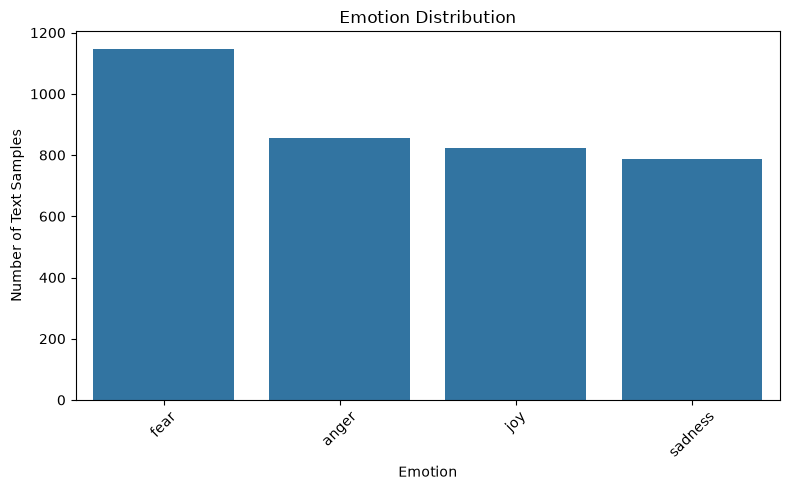

In [5]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="label",
    order=df["label"].value_counts().index
)

plt.title("Emotion Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of Text Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

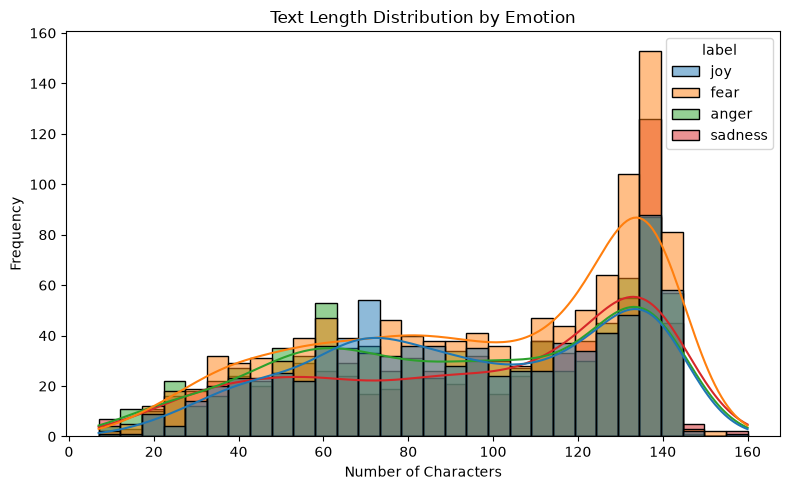

In [6]:
df["text_length"] = df["text"].astype(str).apply(len)

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="text_length",
    hue="label",
    bins=30,
    kde=True
)

plt.title("Text Length Distribution by Emotion")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

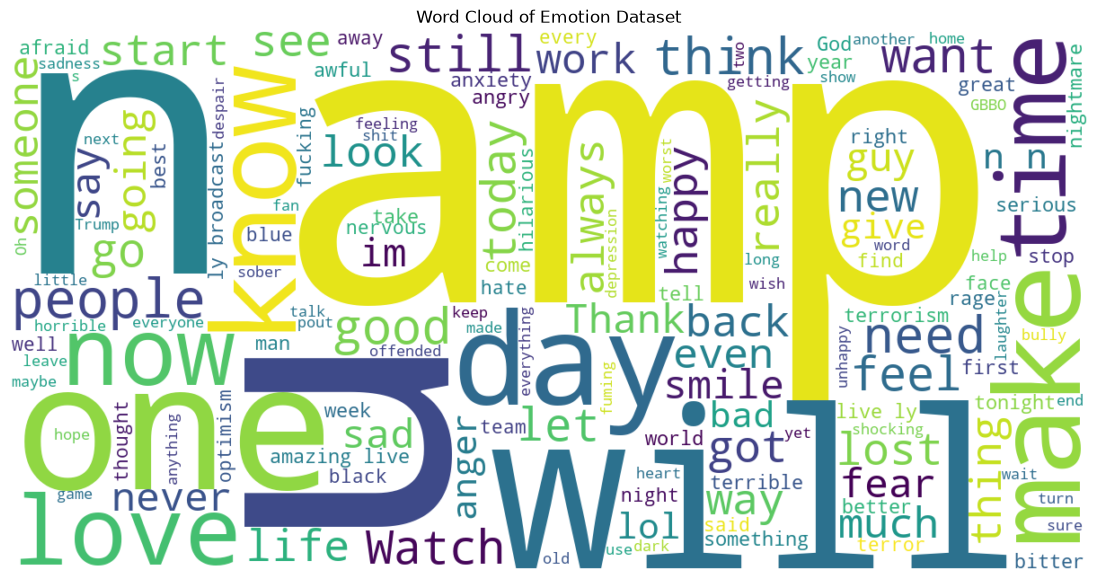

In [7]:
# Combine all text into one string
all_text = " ".join(df["text"].dropna().astype(str))

# Generate Word Cloud
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=150
).generate(all_text)

# Display Word Cloud
plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Emotion Dataset")
plt.show()

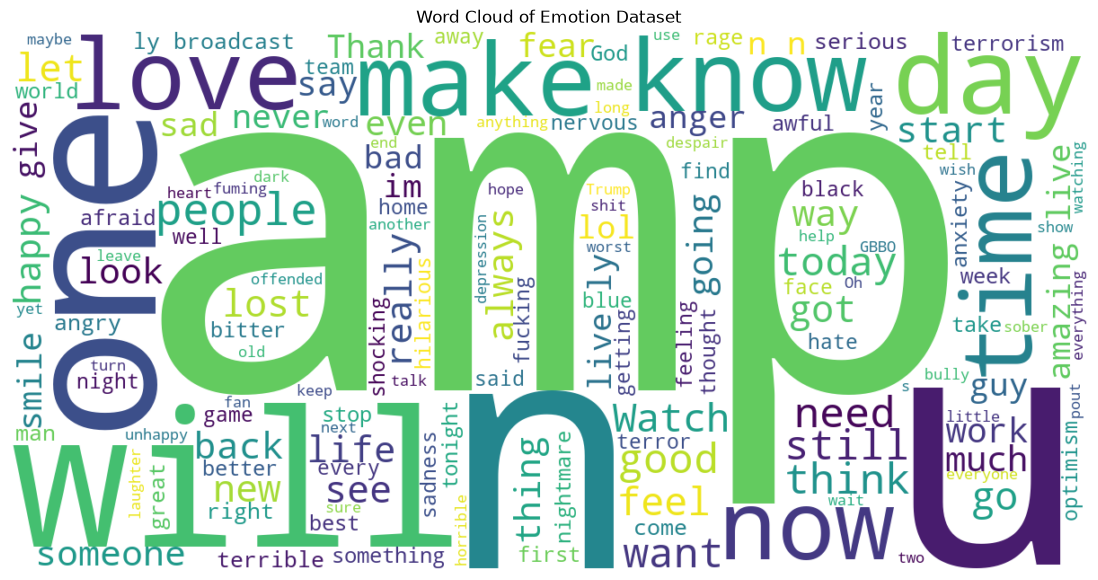

In [8]:
all_text = " ".join(df["text"].dropna().astype(str))

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=150
).generate(all_text)

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Emotion Dataset")
plt.show()

In [10]:
import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")

print("NLTK resources downloaded successfully!")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\SHRAVANI\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\SHRAVANI\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\SHRAVANI\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\SHRAVANI\AppData\Roaming\nltk_data...


NLTK resources downloaded successfully!


[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\SHRAVANI\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [11]:
import re
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

stop_words = set(stopwords.words("english"))

# Preserve important negation words
negation_words = {"not", "no", "nor", "never"}
stop_words = stop_words - negation_words

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()


def preprocess_text(text):
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Keep only letters and spaces
    text = re.sub(r"[^a-z\s]", " ", text)

    # Tokenize text
    words = text.split()

    # Remove stopwords, preserving negations
    words = [word for word in words if word not in stop_words]

    # Apply stemming
    stemmed_words = [stemmer.stem(word) for word in words]

    # Apply lemmatization
    lemmatized_words = [
        lemmatizer.lemmatize(word) for word in stemmed_words
    ]

    return " ".join(lemmatized_words)


df["clean_text"] = df["text"].apply(preprocess_text)

print("Text preprocessing completed!")
display(df[["text", "clean_text", "label"]].head())

Text preprocessing completed!


,text,clean_text,label
0,Just got back from seeing @GaryDelaney in Burs...,got back see garydelaney burslem amaz face sti...,joy
1,Oh dear an evening of absolute hilarity I don'...,oh dear even absolut hilar think laugh much lo...,joy
2,Been waiting all week for this game ❤️❤️❤️ #ch...,wait week game cheer friday,joy
3,"@gardiner_love : Thank you so much, Gloria! Yo...",gardin love thank much gloria sweet thought ma...,joy
4,I feel so blessed to work with the family that...,feel bless work famili nanni noth love amp app...,joy


In [12]:
# ============================================================
# STEP 5.1: TEXT CLEANING FUNCTION
# ============================================================

def clean_text(text):
    """
    Clean text for emotion classification.
    """

    # Convert to string
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove mentions such as @username
    text = re.sub(r'@\w+', '', text)

    # Remove hashtag symbol but keep the word
    # Example: #happy -> happy
    text = re.sub(r'#', '', text)

    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Remove numbers
    text = re.sub(r'\d+', '', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [13]:
import string
import re

print("Required modules imported successfully!")

Required modules imported successfully!


In [14]:
# ============================================================
# STEP 5.2: CREATE CLEAN TEXT COLUMN
# ============================================================

df['text_clean'] = df['text'].apply(clean_text)

print("Text cleaning completed.")

Text cleaning completed.


In [15]:
# ============================================================
# STEP 5.3: COMPARE ORIGINAL AND CLEAN TEXT
# ============================================================

comparison = df[['text', 'text_clean']].head(10)

display(comparison)

,text,text_clean
0,Just got back from seeing @GaryDelaney in Burs...,just got back from seeing in burslem amazing f...
1,Oh dear an evening of absolute hilarity I don'...,oh dear an evening of absolute hilarity i dont...
2,Been waiting all week for this game ❤️❤️❤️ #ch...,been waiting all week for this game ❤️❤️❤️ che...
3,"@gardiner_love : Thank you so much, Gloria! Yo...",thank you so much gloria youre so sweet and th...
4,I feel so blessed to work with the family that...,i feel so blessed to work with the family that...
5,"Today I reached 1000 subscribers on YT!! , #go...",today i reached subscribers on yt goodday than...
6,"@Singaholic121 Good morning, love! Happy first...",good morning love happy first day of fall lets...
7,#BridgetJonesBaby is the best thing I've seen ...,bridgetjonesbaby is the best thing ive seen in...
8,Just got back from seeing @GaryDelaney in Burs...,just got back from seeing in burslem amazing f...
9,@IndyMN I thought the holidays could not get a...,i thought the holidays could not get any more ...


In [16]:
# ============================================================
# STEP 5.4: CHECK EMPTY CLEANED TEXT
# ============================================================

empty_clean_text = (
    df['text_clean']
    .fillna('')
    .str.strip()
    .eq('')
    .sum()
)

print("Empty cleaned text records:", empty_clean_text)

Empty cleaned text records: 0


In [17]:
# ============================================================
# STEP 5.5: CALCULATE TEXT LENGTH
# ============================================================

df['word_count'] = df['text_clean'].apply(
    lambda x: len(x.split())
)

df['character_count'] = df['text_clean'].apply(
    lambda x: len(x)
)

print(df[['word_count', 'character_count']].describe())

        word_count  character_count
count  3613.000000      3613.000000
mean     15.189593        82.462220
std       6.616181        35.048598
min       1.000000         5.000000
25%      10.000000        54.000000
50%      16.000000        86.000000
75%      21.000000       114.000000
max      32.000000       145.000000


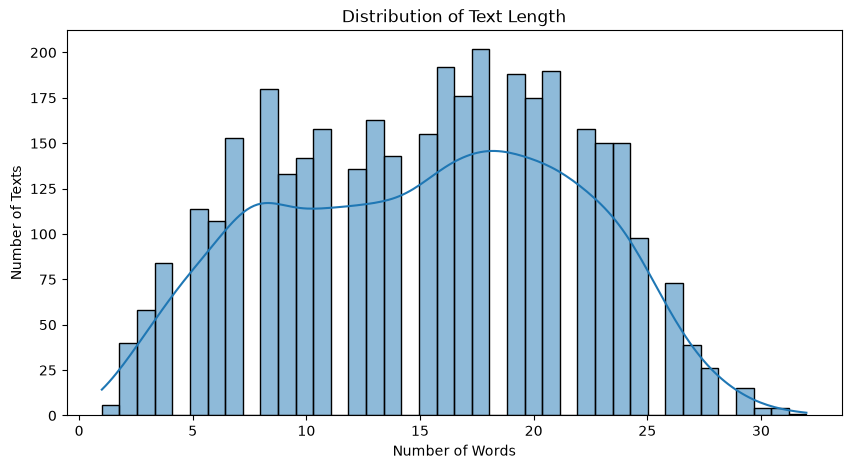

In [18]:
# ============================================================
# STEP 5.6: WORD COUNT DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 5))

sns.histplot(
    df['word_count'],
    bins=40,
    kde=True
)

plt.title('Distribution of Text Length')
plt.xlabel('Number of Words')
plt.ylabel('Number of Texts')

plt.show()

In [19]:
# ============================================================
# STEP 5.7: TEXT LENGTH PERCENTILES
# ============================================================

percentiles = df['word_count'].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
)

print("Text length percentiles:")
print(percentiles)

Text length percentiles:
0.50    16.0
0.75    21.0
0.90    24.0
0.95    25.0
0.99    28.0
Name: word_count, dtype: float64


In [20]:
# ============================================================
# STEP 5.8: REMOVE EMPTY CLEANED TEXTS
# ============================================================

before = len(df)

df = df[
    df['text_clean'].fillna('').str.strip() != ''
].copy()

after = len(df)

print("Rows before removing empty texts:", before)
print("Rows after removing empty texts :", after)
print("Rows removed                    :", before - after)

Rows before removing empty texts: 3613
Rows after removing empty texts : 3613
Rows removed                    : 0


In [21]:
# ============================================================
# STEP 6.1: IDENTIFY CONFLICTING TEXT-LABEL PAIRS
# ============================================================

text_label_counts = (
    df.groupby('text')['label']
      .nunique()
)

conflicting_texts = text_label_counts[
    text_label_counts > 1
].index

print("Number of unique texts with conflicting labels:",
      len(conflicting_texts))

Number of unique texts with conflicting labels: 48


In [22]:
conflicting_mask = df['text'].isin(conflicting_texts)

print("Total conflicting rows:", conflicting_mask.sum())
print("Total dataset rows:", len(df))

percentage_removed = (conflicting_mask.sum() / len(df)) * 100

print("Percentage of rows affected:", round(percentage_removed, 2), "%")

Total conflicting rows: 96
Total dataset rows: 3613
Percentage of rows affected: 2.66 %


In [23]:
df_clean = df[
    ~df['text'].isin(conflicting_texts)
].copy()

print("Original dataset size:", len(df))
print("Clean dataset size   :", len(df_clean))
print("Rows removed         :", len(df) - len(df_clean))

Original dataset size: 3613
Clean dataset size   : 3517
Rows removed         : 96


In [24]:
df_clean = df_clean.reset_index(drop=True)

print("Index reset successfully.")
print(df_clean.head())

Index reset successfully.
                                                text label  text_length  \
0  Just got back from seeing @GaryDelaney in Burs...   joy          110   
1  Oh dear an evening of absolute hilarity I don'...   joy           94   
2  Been waiting all week for this game ❤️❤️❤️ #ch...   joy           60   
3  @gardiner_love : Thank you so much, Gloria! Yo...   joy          129   
4  I feel so blessed to work with the family that...   joy          114   

                                          clean_text  \
0  got back see garydelaney burslem amaz face sti...   
1  oh dear even absolut hilar think laugh much lo...   
2                        wait week game cheer friday   
3  gardin love thank much gloria sweet thought ma...   
4  feel bless work famili nanni noth love amp app...   

                                          text_clean  word_count  \
0  just got back from seeing in burslem amazing f...          16   
1  oh dear an evening of absolute hilarity i dont.

In [25]:
required_columns = ['text', 'text_clean', 'label']

df_clean = df_clean[required_columns].copy()

print("Final columns:")
print(df_clean.columns.tolist())

Final columns:
['text', 'text_clean', 'label']


In [26]:
remaining_duplicates = df_clean['text'].duplicated().sum()

print("Remaining duplicate text entries:", remaining_duplicates)

Remaining duplicate text entries: 0


In [27]:
print(df_clean.isnull().sum())

text          0
text_clean    0
label         0
dtype: int64


In [28]:
print("Final dataset shape:", df_clean.shape)

Final dataset shape: (3517, 3)


In [29]:
print("Final emotion distribution:")
print(df_clean['label'].value_counts())

print("\nFinal emotion percentages:")
print((df_clean['label'].value_counts(normalize=True) * 100).round(2))

Final emotion distribution:
label
fear       1125
anger       829
joy         821
sadness     742
Name: count, dtype: int64

Final emotion percentages:
label
fear       31.99
anger      23.57
joy        23.34
sadness    21.10
Name: proportion, dtype: float64


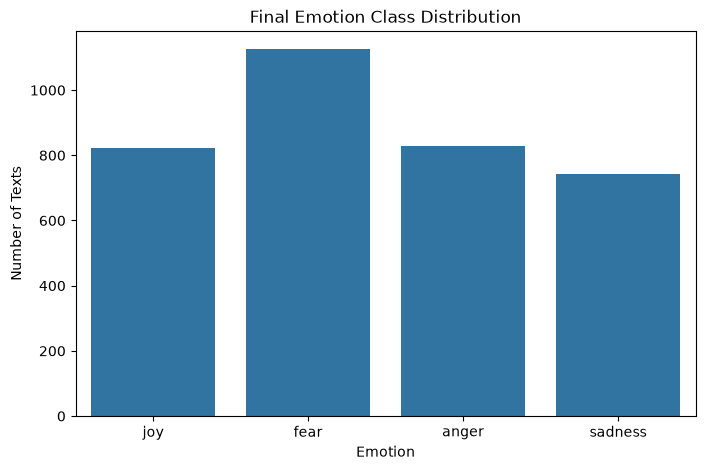

In [30]:
# ============================================================
# STEP 6.11: FINAL CLASS DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x='label'
)

plt.title('Final Emotion Class Distribution')
plt.xlabel('Emotion')
plt.ylabel('Number of Texts')

plt.show()

In [31]:
# ============================================================
# STEP 6.12: SAVE CLEANED DATASET
# ============================================================

df_clean.to_csv(
    "emotion_dataset_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [32]:
# ============================================================
# STEP 7.1: FINAL DATASET CHECK
# ============================================================

print("Final Dataset Shape:", df_clean.shape)

print("\nFinal Columns:")
print(df_clean.columns.tolist())

print("\nFirst 5 Rows:")
display(df_clean.head())

Final Dataset Shape: (3517, 3)

Final Columns:
['text', 'text_clean', 'label']

First 5 Rows:


,text,text_clean,label
0,Just got back from seeing @GaryDelaney in Burs...,just got back from seeing in burslem amazing f...,joy
1,Oh dear an evening of absolute hilarity I don'...,oh dear an evening of absolute hilarity i dont...,joy
2,Been waiting all week for this game ❤️❤️❤️ #ch...,been waiting all week for this game ❤️❤️❤️ che...,joy
3,"@gardiner_love : Thank you so much, Gloria! Yo...",thank you so much gloria youre so sweet and th...,joy
4,I feel so blessed to work with the family that...,i feel so blessed to work with the family that...,joy


In [33]:
# ============================================================
# STEP 7.2: EMOTION DISTRIBUTION
# ============================================================

print("Emotion Distribution:")
print(df_clean['label'].value_counts())

Emotion Distribution:
label
fear       1125
anger       829
joy         821
sadness     742
Name: count, dtype: int64


In [34]:
emotion_percentages = (
    df_clean['label']
    .value_counts(normalize=True) * 100
)

print("\nEmotion percentages:")
print(emotion_percentages.round(2))


Emotion percentages:
label
fear       31.99
anger      23.57
joy        23.34
sadness    21.10
Name: proportion, dtype: float64


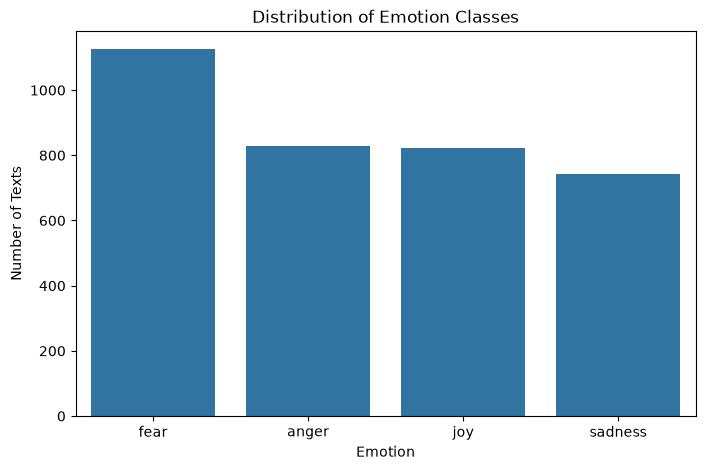

In [35]:
# ============================================================
# STEP 7.3: EMOTION DISTRIBUTION GRAPH
# ============================================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x='label',
    order=df_clean['label'].value_counts().index
)

plt.title('Distribution of Emotion Classes')
plt.xlabel('Emotion')
plt.ylabel('Number of Texts')

plt.show()

In [36]:
# ============================================================
# STEP 7.4: WORD COUNT
# ============================================================

df_clean['word_count'] = (
    df_clean['text_clean']
    .apply(lambda x: len(x.split()))
)

print(df_clean['word_count'].describe())

count    3517.000000
mean       15.160080
std         6.617987
min         1.000000
25%        10.000000
50%        16.000000
75%        21.000000
max        32.000000
Name: word_count, dtype: float64


In [37]:
# ============================================================
# CHARACTER COUNT
# ============================================================

df_clean['character_count'] = (
    df_clean['text_clean']
    .apply(len)
)

print(df_clean['character_count'].describe())

count    3517.000000
mean       82.312767
std        35.117688
min         5.000000
25%        53.000000
50%        86.000000
75%       114.000000
max       145.000000
Name: character_count, dtype: float64


In [38]:
# Add word_count column to df_clean
df_clean['word_count'] = df_clean['text_clean'].apply(
    lambda x: len(str(x).split())
)

print(df_clean[['text_clean', 'word_count']].head())

                                          text_clean  word_count
0  just got back from seeing in burslem amazing f...          16
1  oh dear an evening of absolute hilarity i dont...          20
2  been waiting all week for this game ❤️❤️❤️ che...          11
3  thank you so much gloria youre so sweet and th...          22
4  i feel so blessed to work with the family that...          22


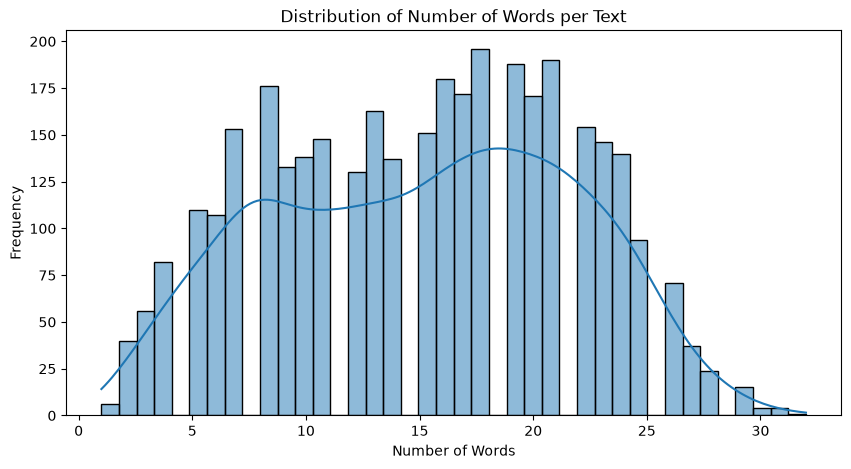

In [39]:
# ============================================================
# STEP 7.5: WORD COUNT DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean['word_count'],
    bins=40,
    kde=True
)

plt.title('Distribution of Number of Words per Text')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')

plt.show()

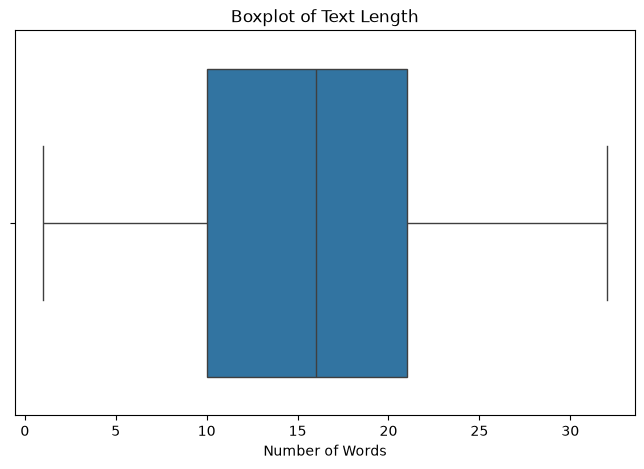

In [40]:
# ============================================================
# STEP 7.6: TEXT LENGTH BOXPLOT
# ============================================================

plt.figure(figsize=(8, 5))

sns.boxplot(
    x=df_clean['word_count']
)

plt.title('Boxplot of Text Length')
plt.xlabel('Number of Words')

plt.show()

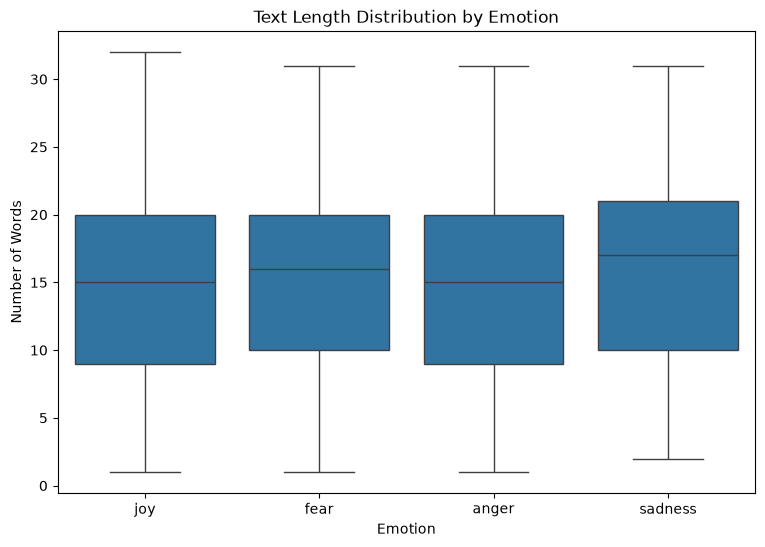

In [41]:
# ============================================================
# STEP 7.7: TEXT LENGTH BY EMOTION
# ============================================================

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df_clean,
    x='label',
    y='word_count'
)

plt.title('Text Length Distribution by Emotion')
plt.xlabel('Emotion')
plt.ylabel('Number of Words')

plt.show()

In [42]:
# ============================================================
# STEP 7.8: TEXT LENGTH STATISTICS BY EMOTION
# ============================================================

length_by_emotion = (
    df_clean
    .groupby('label')['word_count']
    .agg(['count', 'mean', 'median', 'min', 'max'])
    .round(2)
)

display(length_by_emotion)

,count,mean,median,min,max
label,,,,,
anger,829,14.80,15.0,1,31
fear,1125,15.34,16.0,1,31
joy,821,14.70,15.0,1,32
sadness,742,15.79,17.0,2,31


In [43]:
# ============================================================
# STEP 7.9: MOST FREQUENT WORDS
# ============================================================

from collections import Counter

all_words = ' '.join(
    df_clean['text_clean']
).split()

word_frequency = Counter(all_words)

print("Total word tokens:", len(all_words))
print("Unique words:", len(word_frequency))

print("\nTop 30 most frequent words:")

for word, count in word_frequency.most_common(30):
    print(f"{word:20} {count}")

Total word tokens: 53318
Unique words: 8738

Top 30 most frequent words:
the                  1671
to                   1266
i                    1207
a                    1158
and                  921
of                   766
is                   761
you                  680
in                   606
my                   516
it                   469
that                 460
for                  430
be                   373
on                   372
me                   368
this                 327
im                   320
so                   319
have                 305
just                 297
not                  294
but                  284
with                 272
at                   259
its                  246
all                  226
like                 226
was                  224
are                  220


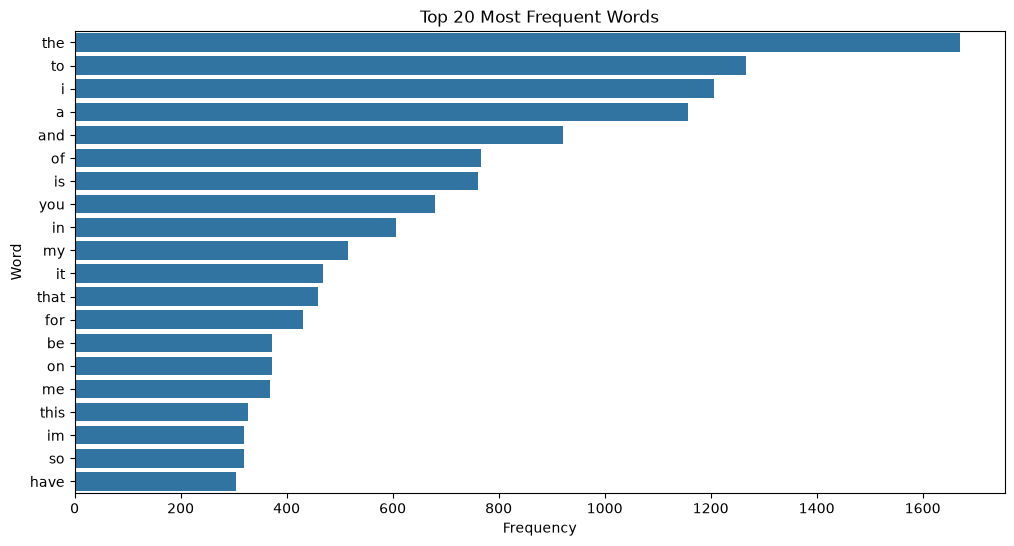

In [44]:
# ============================================================
# STEP 7.10: TOP WORDS VISUALIZATION
# ============================================================

top_words = word_frequency.most_common(20)

words = [item[0] for item in top_words]
counts = [item[1] for item in top_words]

plt.figure(figsize=(12, 6))

sns.barplot(
    x=counts,
    y=words
)

plt.title('Top 20 Most Frequent Words')
plt.xlabel('Frequency')
plt.ylabel('Word')

plt.show()

In [45]:
# ============================================================
# STEP 7.11: REMOVE TEMPORARY EDA COLUMNS
# ============================================================

df_clean = df_clean.drop(
    columns=['word_count', 'character_count']
)

print("Final columns:")
print(df_clean.columns.tolist())

Final columns:
['text', 'text_clean', 'label']


In [46]:
# ============================================================
# STEP 7.12: FINAL EDA CHECK
# ============================================================

print("Final dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nClass distribution:")
print(df_clean['label'].value_counts())

Final dataset shape: (3517, 3)

Missing values:
text          0
text_clean    0
label         0
dtype: int64

Class distribution:
label
fear       1125
anger       829
joy         821
sadness     742
Name: count, dtype: int64


In [47]:
X = df_clean['text_clean']

In [48]:
y = df_clean['label']

In [49]:
# ============================================================
# STEP 8.1: SEPARATE FEATURES AND TARGET
# ============================================================

X = df_clean['text_clean']
y = df_clean['label']

print("Input X shape:", X.shape)
print("Target y shape:", y.shape)

print("\nSample input:")
print(X.head())

print("\nSample target:")
print(y.head())

Input X shape: (3517,)
Target y shape: (3517,)

Sample input:
0    just got back from seeing in burslem amazing f...
1    oh dear an evening of absolute hilarity i dont...
2    been waiting all week for this game ❤️❤️❤️ che...
3    thank you so much gloria youre so sweet and th...
4    i feel so blessed to work with the family that...
Name: text_clean, dtype: str

Sample target:
0    joy
1    joy
2    joy
3    joy
4    joy
Name: label, dtype: str


In [50]:
# ============================================================
# STEP 8.2: TRAIN/VALIDATION + TEST SPLIT
# ============================================================

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.10,
    stratify=y
)

print("Training + Validation samples:", len(X_train_val))
print("Test samples:", len(X_test))

Training + Validation samples: 3165
Test samples: 352


In [51]:
# ============================================================
# STEP 8.3: TRAIN/VALIDATION SPLIT
# ============================================================

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.111111,
    stratify=y_train_val
)

print("Training samples   :", len(X_train))
print("Validation samples :", len(X_val))
print("Test samples       :", len(X_test))

Training samples   : 2813
Validation samples : 352
Test samples       : 352


In [52]:
# ============================================================
# STEP 8.4: CHECK SPLIT PERCENTAGES
# ============================================================

total_samples = len(df_clean)

print(
    "Training percentage   :",
    round(len(X_train) / total_samples * 100, 2),
    "%"
)

print(
    "Validation percentage:",
    round(len(X_val) / total_samples * 100, 2),
    "%"
)

print(
    "Test percentage       :",
    round(len(X_test) / total_samples * 100, 2),
    "%"
)

Training percentage   : 79.98 %
Validation percentage: 10.01 %
Test percentage       : 10.01 %


In [53]:
# ============================================================
# STEP 8.5: CHECK CLASS DISTRIBUTION
# ============================================================

print("========== TRAINING ==========")
print(y_train.value_counts())
print("\nPercentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\n========== VALIDATION ==========")
print(y_val.value_counts())
print("\nPercentages:")
print((y_val.value_counts(normalize=True) * 100).round(2))

print("\n========== TEST ==========")
print(y_test.value_counts())
print("\nPercentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))

========== TRAINING ==========
label
fear       899
anger      663
joy        657
sadness    594
Name: count, dtype: int64

Percentages:
label
fear       31.96
anger      23.57
joy        23.36
sadness    21.12
Name: proportion, dtype: float64

========== VALIDATION ==========
label
fear       113
anger       83
joy         82
sadness     74
Name: count, dtype: int64

Percentages:
label
fear       32.10
anger      23.58
joy        23.30
sadness    21.02
Name: proportion, dtype: float64

========== TEST ==========
label
fear       113
anger       83
joy         82
sadness     74
Name: count, dtype: int64

Percentages:
label
fear       32.10
anger      23.58
joy        23.30
sadness    21.02
Name: proportion, dtype: float64


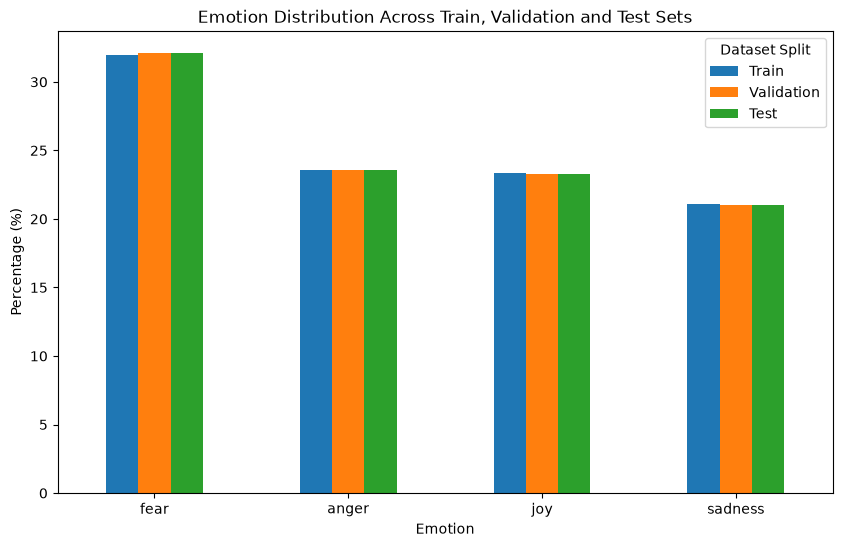

In [54]:
# ============================================================
# STEP 8.6: CLASS DISTRIBUTION ACROSS SPLITS
# ============================================================

train_dist = y_train.value_counts(normalize=True) * 100
val_dist = y_val.value_counts(normalize=True) * 100
test_dist = y_test.value_counts(normalize=True) * 100

distribution_df = pd.DataFrame({
    'Train': train_dist,
    'Validation': val_dist,
    'Test': test_dist
}).fillna(0)

distribution_df.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Emotion Distribution Across Train, Validation and Test Sets')
plt.xlabel('Emotion')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Dataset Split')

plt.show()


In [55]:
# ============================================================
# STEP 8.7: CHECK TRAIN-TEST TEXT OVERLAP
# ============================================================

train_texts = set(X_train)
test_texts = set(X_test)

overlap = train_texts.intersection(test_texts)

print("Number of overlapping texts between train and test:",
      len(overlap))

Number of overlapping texts between train and test: 2


In [56]:
# ============================================================
# STEP 8.8: CHECK VALIDATION-TEST OVERLAP
# ============================================================

val_texts = set(X_val)

val_test_overlap = val_texts.intersection(test_texts)

print(
    "Validation-Test overlapping texts:",
    len(val_test_overlap)
)

Validation-Test overlapping texts: 2


In [57]:
# ============================================================
# STEP 8.9: CHECK TRAIN-VALIDATION OVERLAP
# ============================================================

train_val_overlap = train_texts.intersection(val_texts)

print(
    "Train-Validation overlapping texts:",
    len(train_val_overlap)
)

Train-Validation overlapping texts: 4


In [58]:
# ============================================================
# STEP 8.1: CHECK REMAINING DUPLICATE TEXTS
# ============================================================

duplicate_count = df_clean['text'].duplicated().sum()

print("Remaining duplicate text rows:", duplicate_count)

Remaining duplicate text rows: 0


In [59]:
# ============================================================
# STEP 8.2: REMOVE DUPLICATE TEXTS
# ============================================================

before_duplicates = len(df_clean)

df_clean = df_clean.drop_duplicates(
    subset='text',
    keep='first'
).reset_index(drop=True)

after_duplicates = len(df_clean)

print("Rows before duplicate removal:", before_duplicates)
print("Rows after duplicate removal :", after_duplicates)
print("Duplicate rows removed       :", before_duplicates - after_duplicates)

Rows before duplicate removal: 3517
Rows after duplicate removal : 3517
Duplicate rows removed       : 0


In [60]:
# ============================================================
# STEP 8.3: VERIFY DUPLICATE REMOVAL
# ============================================================

print(
    "Remaining duplicate texts:",
    df_clean['text'].duplicated().sum()
)

Remaining duplicate texts: 0


In [61]:
# ============================================================
# STEP 8.4: FINAL LABEL CONSISTENCY CHECK
# ============================================================

label_consistency = (
    df_clean.groupby('text')['label']
            .nunique()
)

remaining_conflicts = (
    label_consistency > 1
).sum()

print("Texts with conflicting labels:", remaining_conflicts)

Texts with conflicting labels: 0


In [62]:
# ============================================================
# STEP 8.5: RECREATE INPUT AND TARGET
# ============================================================

X = df_clean['text_clean']
y = df_clean['label']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3517,)
y shape: (3517,)


In [63]:
# ============================================================
# STEP 8.6: CREATE TRAIN/VALIDATION/TEST SPLITS AGAIN
# ============================================================

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.10,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.111111,
    stratify=y_train_val
)

print("Training samples   :", len(X_train))
print("Validation samples :", len(X_val))
print("Test samples       :", len(X_test))

Training samples   : 2813
Validation samples : 352
Test samples       : 352


In [64]:
# ============================================================
# STEP 8.7: FINAL OVERLAP CHECK
# ============================================================

train_texts = set(X_train)
val_texts = set(X_val)
test_texts = set(X_test)

train_test_overlap = train_texts.intersection(test_texts)
train_val_overlap = train_texts.intersection(val_texts)
val_test_overlap = val_texts.intersection(test_texts)

print("Train-Test overlap       =", len(train_test_overlap))
print("Train-Validation overlap =", len(train_val_overlap))
print("Validation-Test overlap  =", len(val_test_overlap))


Train-Test overlap       = 2
Train-Validation overlap = 3
Validation-Test overlap  = 2


In [65]:
# ============================================================
# STEP 8 — FINAL DUPLICATE REMOVAL AND DATA SPLITTING
# ============================================================

# Work on a fresh copy
df_final = df_clean.copy()

# ------------------------------------------------------------
# 1. Check duplicate cleaned texts
# ------------------------------------------------------------
print("Duplicate cleaned texts before removal:",
      df_final['text_clean'].duplicated().sum())

# ------------------------------------------------------------
# 2. Remove duplicate cleaned texts
# ------------------------------------------------------------
df_final = df_final.drop_duplicates(
    subset='text_clean',
    keep='first'
).reset_index(drop=True)

print("Duplicate cleaned texts after removal:",
      df_final['text_clean'].duplicated().sum())

print("\nFinal dataset shape:", df_final.shape)

# ------------------------------------------------------------
# 3. Verify there are no conflicting labels
# ------------------------------------------------------------
conflicting_cleaned = (
    df_final.groupby('text_clean')['label']
    .nunique()
)

conflicting_cleaned = conflicting_cleaned[
    conflicting_cleaned > 1
]

print("Conflicting cleaned texts:", len(conflicting_cleaned))

# ------------------------------------------------------------
# 4. Define X and y
# ------------------------------------------------------------
X = df_final['text_clean']
y = df_final['label']

# ------------------------------------------------------------
# 5. First split: 90% temporary + 10% test
# ------------------------------------------------------------
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.10,
    stratify=y,
   
)

# ------------------------------------------------------------
# 6. Second split: 80% train + 10% validation
# ------------------------------------------------------------
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=1/9,
    stratify=y_temp,
    
)

# ------------------------------------------------------------
# 7. Reset indexes
# ------------------------------------------------------------
X_train = X_train.reset_index(drop=True)
X_val = X_val.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

y_train = y_train.reset_index(drop=True)
y_val = y_val.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

# ------------------------------------------------------------
# 8. Check dataset sizes
# ------------------------------------------------------------
print("\nDataset sizes:")
print("Training   :", len(X_train))
print("Validation :", len(X_val))
print("Testing    :", len(X_test))

# ------------------------------------------------------------
# 9. Check class distributions
# ------------------------------------------------------------
print("\nTraining distribution:")
print(y_train.value_counts())

print("\nValidation distribution:")
print(y_val.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

# ------------------------------------------------------------
# 10. Check text overlap
# ------------------------------------------------------------
train_texts = set(X_train)
val_texts = set(X_val)
test_texts = set(X_test)

train_test_overlap = train_texts.intersection(test_texts)
train_val_overlap = train_texts.intersection(val_texts)
val_test_overlap = val_texts.intersection(test_texts)

print("\n============================================================")
print("FINAL DATA LEAKAGE CHECK")
print("============================================================")

print("Train-Test overlap       =", len(train_test_overlap))
print("Train-Validation overlap =", len(train_val_overlap))
print("Validation-Test overlap  =", len(val_test_overlap))

# ------------------------------------------------------------
# 11. Final confirmation
# ------------------------------------------------------------
if (
    len(train_test_overlap) == 0
    and len(train_val_overlap) == 0
    and len(val_test_overlap) == 0
):
    print("\n✅ SUCCESS: No text overlap between train, validation and test sets.")
else:
    print("\n❌ WARNING: Overlap still exists. Do not continue yet.")

Duplicate cleaned texts before removal: 48
Duplicate cleaned texts after removal: 0

Final dataset shape: (3469, 3)
Conflicting cleaned texts: 0

Dataset sizes:
Training   : 2775
Validation : 347
Testing    : 347

Training distribution:
label
fear       900
anger      662
joy        620
sadness    593
Name: count, dtype: int64

Validation distribution:
label
fear       112
anger       83
joy         78
sadness     74
Name: count, dtype: int64

Testing distribution:
label
fear       113
anger       83
joy         77
sadness     74
Name: count, dtype: int64

FINAL DATA LEAKAGE CHECK
Train-Test overlap       = 0
Train-Validation overlap = 0
Validation-Test overlap  = 0

✅ SUCCESS: No text overlap between train, validation and test sets.


In [66]:
# ============================================================
# STEP 9 — LABEL ENCODING
# ============================================================

from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

# Create LabelEncoder
label_encoder = LabelEncoder()

# Fit ONLY on training labels
y_train_encoded = label_encoder.fit_transform(y_train)

# Transform validation and test labels
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

# Number of emotion classes
num_classes = len(label_encoder.classes_)

# Display mapping
print("Emotion Label Mapping:")
for index, emotion in enumerate(label_encoder.classes_):
    print(f"{emotion} -> {index}")

print("\nNumber of classes:", num_classes)

# Display encoded samples
print("\nFirst 10 training labels:")
print(y_train.iloc[:10].values)

print("\nFirst 10 encoded training labels:")
print(y_train_encoded[:10])

Emotion Label Mapping:
anger -> 0
fear -> 1
joy -> 2
sadness -> 3

Number of classes: 4

First 10 training labels:
<ArrowStringArray>
[  'anger',   'anger',   'anger',   'anger',    'fear', 'sadness',     'joy',
    'fear',    'fear',     'joy']
Length: 10, dtype: str

First 10 encoded training labels:
[0 0 0 0 1 3 2 1 1 2]


In [67]:
# ------------------------------------------------------------
# Convert integer labels to one-hot encoded labels
# ------------------------------------------------------------

y_train_cat = to_categorical(
    y_train_encoded,
    num_classes=num_classes
)

y_val_cat = to_categorical(
    y_val_encoded,
    num_classes=num_classes
)

y_test_cat = to_categorical(
    y_test_encoded,
    num_classes=num_classes
)

# Display shapes
print("Encoded label shapes:")
print("y_train_encoded :", y_train_encoded.shape)
print("y_val_encoded   :", y_val_encoded.shape)
print("y_test_encoded  :", y_test_encoded.shape)

print("\nOne-hot encoded shapes:")
print("y_train_cat :", y_train_cat.shape)
print("y_val_cat   :", y_val_cat.shape)
print("y_test_cat  :", y_test_cat.shape)

# Display examples
print("\nExample one-hot labels:")
print(y_train_cat[:5])

Encoded label shapes:
y_train_encoded : (2775,)
y_val_encoded   : (347,)
y_test_encoded  : (347,)

One-hot encoded shapes:
y_train_cat : (2775, 4)
y_val_cat   : (347, 4)
y_test_cat  : (347, 4)

Example one-hot labels:
[[1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [0. 1. 0. 0.]]


In [68]:
# ============================================================
# LABEL ENCODING VERIFICATION
# ============================================================

print("Classes:", label_encoder.classes_)
print("Number of classes:", num_classes)

print("\nUnique encoded training labels:")
print(np.unique(y_train_encoded))

print("\nUnique encoded validation labels:")
print(np.unique(y_val_encoded))

print("\nUnique encoded test labels:")
print(np.unique(y_test_encoded))

print("\nEncoded labels are ready for deep learning.")

Classes: ['anger' 'fear' 'joy' 'sadness']
Number of classes: 4

Unique encoded training labels:
[0 1 2 3]

Unique encoded validation labels:
[0 1 2 3]

Unique encoded test labels:
[0 1 2 3]

Encoded labels are ready for deep learning.


In [69]:
# ============================================================
# STEP 10 — TOKENIZATION
# ============================================================

from tensorflow.keras.preprocessing.text import Tokenizer

# Create tokenizer
tokenizer = Tokenizer(
    oov_token="<OOV>"
)

# Fit tokenizer ONLY on training text
tokenizer.fit_on_texts(X_train)

# Convert text into integer sequences
X_train_sequences = tokenizer.texts_to_sequences(X_train)
X_val_sequences = tokenizer.texts_to_sequences(X_val)
X_test_sequences = tokenizer.texts_to_sequences(X_test)

# Vocabulary size
vocab_size = len(tokenizer.word_index) + 1

print("Vocabulary size:", vocab_size)

print("\nFirst 5 training texts:")
for i in range(5):
    print(f"\nText     : {X_train.iloc[i]}")
    print(f"Sequence : {X_train_sequences[i]}")

Vocabulary size: 7667

First 5 training texts:

Text     : i lowkey forgot you had twitter and if you dont follow me back im gonna be
Sequence : [4, 3434, 501, 9, 84, 291, 6, 35, 9, 33, 338, 17, 91, 19, 279, 16]

Text     : i have rabid grizzly bears im going to scatter in neighborhoods all over americanntheyre poor refugeesnninyourneighborhoodnotdc
Sequence : [4, 20, 578, 3435, 1913, 19, 92, 3, 3436, 10, 3437, 28, 93, 3438, 579, 3439]

Text     : a little nose irritation and a little more chills on my body im so not into flu into flu into flu fallsongs
Sequence : [5, 169, 1397, 1124, 6, 5, 169, 67, 3440, 15, 11, 725, 19, 18, 24, 136, 1398, 136, 1398, 136, 1398, 3441]

Text     : wallah my blood is boiling i need to take a nap ugh
Sequence : [3442, 11, 580, 8, 535, 4, 94, 3, 245, 5, 581, 807]

Text     : and i hope when the police met him at the subway that they took him straight to jail 😕
Sequence : [6, 4, 192, 32, 2, 388, 808, 99, 26, 2, 1914, 12, 51, 453, 99, 536, 3, 1915, 925]


In [70]:
# ------------------------------------------------------------
# Inspect tokenizer vocabulary
# ------------------------------------------------------------

print("Total unique words:", len(tokenizer.word_index))

print("\nFirst 30 words in vocabulary:")

for word, index in list(tokenizer.word_index.items())[:30]:
    print(f"{word} -> {index}")

Total unique words: 7666

First 30 words in vocabulary:
<OOV> -> 1
the -> 2
to -> 3
i -> 4
a -> 5
and -> 6
of -> 7
is -> 8
you -> 9
in -> 10
my -> 11
that -> 12
it -> 13
for -> 14
on -> 15
be -> 16
me -> 17
so -> 18
im -> 19
have -> 20
just -> 21
this -> 22
but -> 23
not -> 24
with -> 25
at -> 26
its -> 27
all -> 28
was -> 29
like -> 30


In [71]:
# ============================================================
# CHECK SEQUENCE LENGTHS
# ============================================================

train_sequence_lengths = [
    len(sequence) for sequence in X_train_sequences
]

val_sequence_lengths = [
    len(sequence) for sequence in X_val_sequences
]

test_sequence_lengths = [
    len(sequence) for sequence in X_test_sequences
]

print("Training sequence length statistics:")
print("Minimum :", min(train_sequence_lengths))
print("Maximum :", max(train_sequence_lengths))
print("Mean    :", np.mean(train_sequence_lengths))
print("Median  :", np.median(train_sequence_lengths))

print("\nValidation sequence length statistics:")
print("Minimum :", min(val_sequence_lengths))
print("Maximum :", max(val_sequence_lengths))
print("Mean    :", np.mean(val_sequence_lengths))
print("Median  :", np.median(val_sequence_lengths))

print("\nTesting sequence length statistics:")
print("Minimum :", min(test_sequence_lengths))
print("Maximum :", max(test_sequence_lengths))
print("Mean    :", np.mean(test_sequence_lengths))
print("Median  :", np.median(test_sequence_lengths))

Training sequence length statistics:
Minimum : 1
Maximum : 32
Mean    : 15.278918918918919
Median  : 16.0

Validation sequence length statistics:
Minimum : 2
Maximum : 28
Mean    : 15.172910662824208
Median  : 15.0

Testing sequence length statistics:
Minimum : 2
Maximum : 31
Mean    : 15.031700288184439
Median  : 16.0


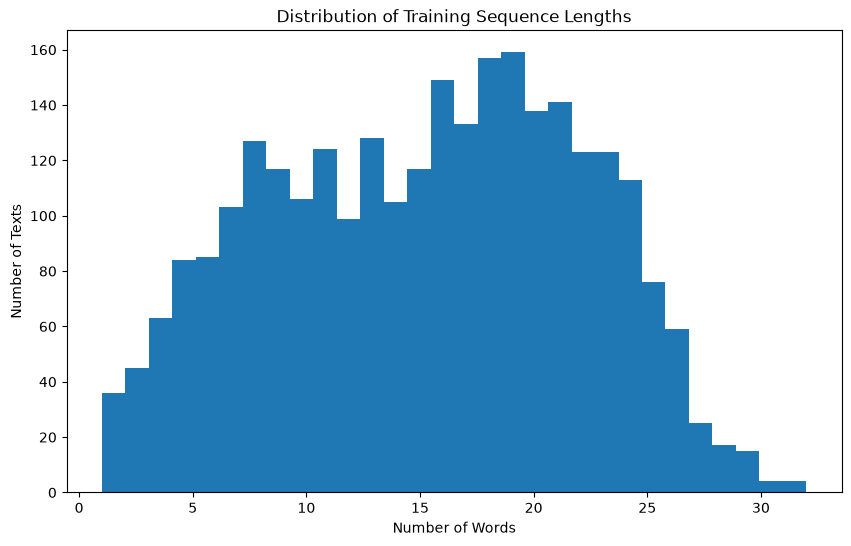

In [72]:
# ============================================================
# SEQUENCE LENGTH DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))

plt.hist(
    train_sequence_lengths,
    bins=30
)

plt.xlabel("Number of Words")
plt.ylabel("Number of Texts")
plt.title("Distribution of Training Sequence Lengths")

plt.show()

In [73]:
# ============================================================
# DETERMINE MAXIMUM SEQUENCE LENGTH
# ============================================================

max_len = int(
    np.percentile(train_sequence_lengths, 95)
)

print("95th percentile sequence length:", max_len)

print("Maximum training sequence length:",
      max(train_sequence_lengths))

print("\nSelected max_len:", max_len)

95th percentile sequence length: 25
Maximum training sequence length: 32

Selected max_len: 25


In [74]:
# ============================================================
# STEP 11 — PADDING THE SEQUENCES
# ============================================================

from tensorflow.keras.preprocessing.sequence import pad_sequences

# Pad training sequences
X_train_padded = pad_sequences(
    X_train_sequences,
    maxlen=max_len,
    padding='post',
    truncating='post'
)

# Pad validation sequences
X_val_padded = pad_sequences(
    X_val_sequences,
    maxlen=max_len,
    padding='post',
    truncating='post'
)

# Pad test sequences
X_test_padded = pad_sequences(
    X_test_sequences,
    maxlen=max_len,
    padding='post',
    truncating='post'
)

# Display shapes
print("Padded sequence shapes:")
print("X_train_padded :", X_train_padded.shape)
print("X_val_padded   :", X_val_padded.shape)
print("X_test_padded  :", X_test_padded.shape)

Padded sequence shapes:
X_train_padded : (2775, 25)
X_val_padded   : (347, 25)
X_test_padded  : (347, 25)


In [75]:
# ------------------------------------------------------------
# Display original sequence and padded sequence
# ------------------------------------------------------------

sample_index = 0

print("Original text:")
print(X_train.iloc[sample_index])

print("\nOriginal sequence:")
print(X_train_sequences[sample_index])

print("\nPadded sequence:")
print(X_train_padded[sample_index])

print("\nOriginal length:",
      len(X_train_sequences[sample_index]))

print("Padded length:",
      len(X_train_padded[sample_index]))

Original text:
i lowkey forgot you had twitter and if you dont follow me back im gonna be

Original sequence:
[4, 3434, 501, 9, 84, 291, 6, 35, 9, 33, 338, 17, 91, 19, 279, 16]

Padded sequence:
[   4 3434  501    9   84  291    6   35    9   33  338   17   91   19
  279   16    0    0    0    0    0    0    0    0    0]

Original length: 16
Padded length: 25


In [76]:
# ============================================================
# VERIFY PADDING
# ============================================================

print("Unique training sequence lengths:",
      np.unique([len(x) for x in X_train_padded]))

print("Unique validation sequence lengths:",
      np.unique([len(x) for x in X_val_padded]))

print("Unique testing sequence lengths:",
      np.unique([len(x) for x in X_test_padded]))

Unique training sequence lengths: [25]
Unique validation sequence lengths: [25]
Unique testing sequence lengths: [25]


In [77]:
# ============================================================
# STEP 12 — WORD2VEC EMBEDDING
# ============================================================

import gensim
from gensim.models import Word2Vec

print("Gensim version:", gensim.__version__)

Gensim version: 4.4.0


In [78]:
# ------------------------------------------------------------
# Convert training text into word lists
# ------------------------------------------------------------

train_sentences = [
    text.split()
    for text in X_train
]

val_sentences = [
    text.split()
    for text in X_val
]

test_sentences = [
    text.split()
    for text in X_test
]

print("Number of training sentences:", len(train_sentences))

print("\nExample:")
print(train_sentences[0])

Number of training sentences: 2775

Example:
['i', 'lowkey', 'forgot', 'you', 'had', 'twitter', 'and', 'if', 'you', 'dont', 'follow', 'me', 'back', 'im', 'gonna', 'be']


In [79]:
# ============================================================
# TRAIN WORD2VEC
# ============================================================

word2vec_model = Word2Vec(
    sentences=train_sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    sg=1,
    epochs=10,
    
)

print("Word2Vec training completed.")

print("Vocabulary size:",
      len(word2vec_model.wv))

print("Embedding dimension:",
      word2vec_model.wv.vector_size)

Word2Vec training completed.
Vocabulary size: 7665
Embedding dimension: 100


In [80]:
# ============================================================
# INSPECT WORD2VEC VECTORS
# ============================================================

sample_words = ['happy', 'sad', 'angry', 'fear']

for word in sample_words:
    if word in word2vec_model.wv:
        print(f"\n{word}:")
        print(word2vec_model.wv[word][:10])


happy:
[ 0.07795343  0.20074618  0.03184369  0.00267227  0.14986844 -0.4497928
  0.19610766  0.56332874 -0.21672423 -0.29738128]

sad:
[-0.02087986  0.19432457 -0.03844962  0.06756982  0.01646459 -0.362226
  0.18345247  0.5105927  -0.2507293  -0.24208422]

angry:
[ 0.02261739  0.17676182  0.00611784  0.05406797  0.05708256 -0.38889176
  0.18926263  0.46957782 -0.2804936  -0.263854  ]

fear:
[-0.00951023  0.18979694  0.03006825  0.05739461  0.04643036 -0.3816369
  0.15344848  0.4365942  -0.23992257 -0.23170757]


In [81]:
# ============================================================
# SIMILAR WORDS
# ============================================================

for word in ['happy', 'sad', 'angry', 'fear']:
    
    if word in word2vec_model.wv:
        print(f"\nWords similar to '{word}':")
        print(word2vec_model.wv.most_similar(word, topn=5))


Words similar to 'happy':
[('discouraged', 0.9737296104431152), ('will', 0.972148060798645), ('smile', 0.9717219471931458), ('everything', 0.9708572626113892), ('youre', 0.9695106148719788)]

Words similar to 'sad':
[('scare', 0.9937774538993835), ('accept', 0.9932012557983398), ('cheerful', 0.9928383231163025), ('pessimist', 0.992572009563446), ('hard', 0.9924304485321045)]

Words similar to 'angry':
[('wonder', 0.9926695227622986), ('laugh', 0.9915440082550049), ('maybe', 0.9913270473480225), ('ask', 0.9905941486358643), ('happen', 0.9904874563217163)]

Words similar to 'fear':
[('hold', 0.9877211451530457), ('shake', 0.9875271916389465), ('lets', 0.9873121380805969), ('sign', 0.9871501922607422), ('words', 0.9870526194572449)]


In [82]:
# ============================================================
# CREATE WORD2VEC EMBEDDING MATRIX
# ============================================================

embedding_dim = 100

embedding_matrix_w2v = np.zeros(
    (vocab_size, embedding_dim)
)

words_found = 0

for word, index in tokenizer.word_index.items():

    if word in word2vec_model.wv:
        embedding_matrix_w2v[index] = word2vec_model.wv[word]
        words_found += 1

print("Embedding matrix shape:",
      embedding_matrix_w2v.shape)

print("Words found in Word2Vec:",
      words_found)

print("Total tokenizer words:",
      len(tokenizer.word_index))

Embedding matrix shape: (7667, 100)
Words found in Word2Vec: 7665
Total tokenizer words: 7666


In [83]:
# ============================================================
# STEP 13 — WORD2VEC + LSTM
# ============================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# ------------------------------------------------------------
# Build Word2Vec + LSTM model
# ------------------------------------------------------------

w2v_lstm_model = Sequential([
    
    # Pretrained Word2Vec embedding
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix_w2v],
        trainable=False,
        mask_zero=True
    ),
    
    # LSTM layer
    LSTM(
        128,
        dropout=0.2
    ),
    
    # Fully connected layer
    Dense(
        64,
        activation='relu'
    ),
    
    # Dropout
    Dropout(0.3),
    
    # Output layer
    Dense(
        num_classes,
        activation='softmax'
    )
])

# Display architecture
w2v_lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │       766,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 766,700 (2.92 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 766,700 (2.92 MB)

In [84]:
# ============================================================
# COMPILE WORD2VEC + LSTM
# ============================================================

w2v_lstm_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully.")

Model compiled successfully.


In [90]:

# ============================================================
# TRAIN WORD2VEC + LSTM
# ============================================================

EPOCHS = 30
BATCH_SIZE = 32

history = w2v_lstm_model.fit(
    X_train_padded,
    y_train_cat,
    validation_data=(X_val_padded, y_val_cat),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
    shuffle=True
)

print("Word2Vec + LSTM Training Completed!")
print(f"Total Epochs Trained: {EPOCHS}")


Epoch 1/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - accuracy: 0.3171 - loss: 1.3784 - val_accuracy: 0.2882 - val_loss: 1.3820
Epoch 2/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.3146 - loss: 1.3779 - val_accuracy: 0.3228 - val_loss: 1.3718
Epoch 3/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.3222 - loss: 1.3730 - val_accuracy: 0.3112 - val_loss: 1.3781
Epoch 4/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.3250 - loss: 1.3715 - val_accuracy: 0.3112 - val_loss: 1.3766
Epoch 5/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.3229 - loss: 1.3683 - val_accuracy: 0.3199 - val_loss: 1.3740
Epoch 6/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.3323 - loss: 1.3681 - val_accuracy: 0.3170 - val_loss: 1.3741
Epoch 7/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.3297 - loss: 1.3621 - val_accuracy: 0.3199 - val_loss: 1.3759
Epoch 8/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.3297 - loss: 1.3603 - val_accuracy: 0.3170 - v

In [91]:

# ============================================================
# TRAIN WORD2VEC + LSTM
# ============================================================

EPOCHS = 20
BATCH_SIZE = 32

history = w2v_lstm_model.fit(
    X_train_padded,
    y_train_cat,
    validation_data=(X_val_padded, y_val_cat),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
    shuffle=True
)

print("Word2Vec + LSTM Training Completed!")
print(f"Total Epochs Trained: {EPOCHS}")


Epoch 1/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.3809 - loss: 1.3216 - val_accuracy: 0.3170 - val_loss: 1.3585
Epoch 2/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.3744 - loss: 1.3104 - val_accuracy: 0.3429 - val_loss: 1.3608
Epoch 3/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.3755 - loss: 1.3220 - val_accuracy: 0.3084 - val_loss: 1.3643
Epoch 4/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.3809 - loss: 1.3117 - val_accuracy: 0.3112 - val_loss: 1.3769
Epoch 5/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.3795 - loss: 1.3103 - val_accuracy: 0.3026 - val_loss: 1.3612
Epoch 6/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.3831 - loss: 1.3056 - val_accuracy: 0.3026 - val_loss: 1.3611
Epoch 7/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.3874 - loss: 1.3018 - val_accuracy: 0.3170 - val_loss: 1.3680
Epoch 8/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.3877 - loss: 1.3015 - val_accuracy: 0.3372 - v

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step
WORD2VEC + LSTM - TEST EVALUATION
Accuracy  : 0.3429
Precision : 0.3353
Recall    : 0.3358
F1-Score  : 0.3326

Classification Report:
              precision    recall  f1-score   support

       anger       0.33      0.24      0.28        83
        fear       0.41      0.42      0.42       113
         joy       0.29      0.29      0.29        77
     sadness       0.32      0.39      0.35        74

    accuracy                           0.34       347
   macro avg       0.34      0.34      0.33       347
weighted avg       0.34      0.34      0.34       347



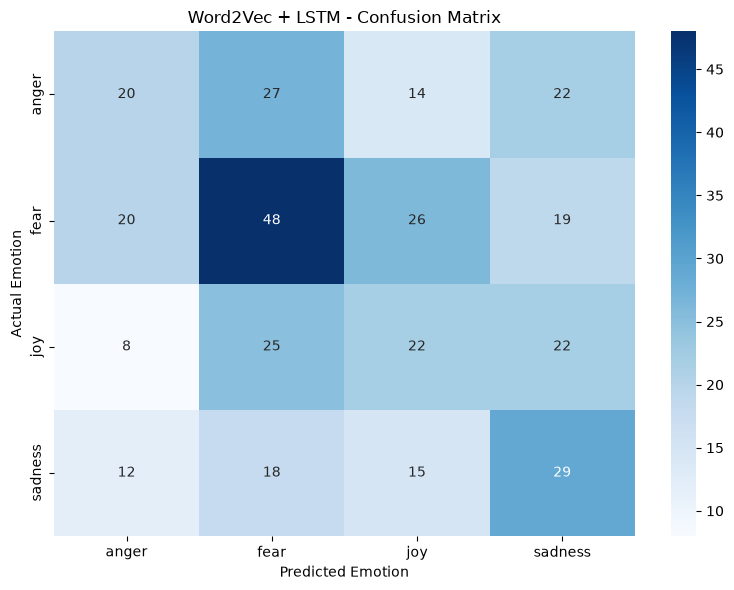

In [92]:

# ============================================================
# EVALUATE WORD2VEC + LSTM MODEL
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Generate predictions
y_test_pred_prob = w2v_lstm_model.predict(X_test_padded)

# Convert probabilities into predicted class labels
y_test_pred = np.argmax(y_test_pred_prob, axis=1)

# Actual test labels
y_test_actual = y_test_encoded

# Calculate evaluation metrics
accuracy = accuracy_score(y_test_actual, y_test_pred)

precision = precision_score(
    y_test_actual, y_test_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_test_actual, y_test_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_test_actual, y_test_pred, average="macro", zero_division=0
)

print("============================================================")
print("WORD2VEC + LSTM - TEST EVALUATION")
print("============================================================")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test_actual,
        y_test_pred,
        labels=np.arange(num_classes),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# Confusion Matrix
cm = confusion_matrix(
    y_test_actual,
    y_test_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Word2Vec + LSTM - Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.show()


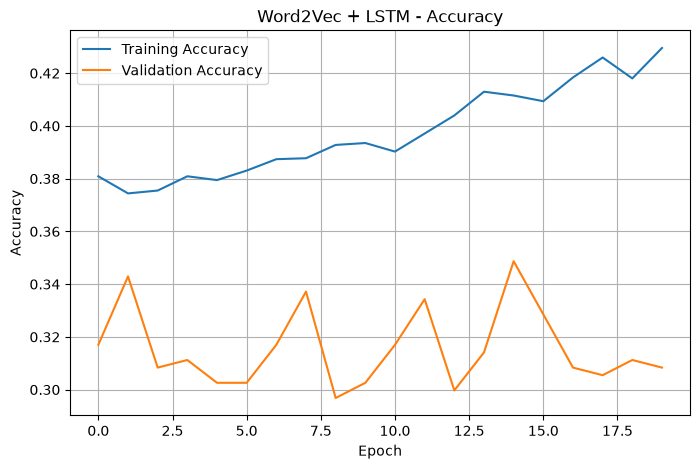

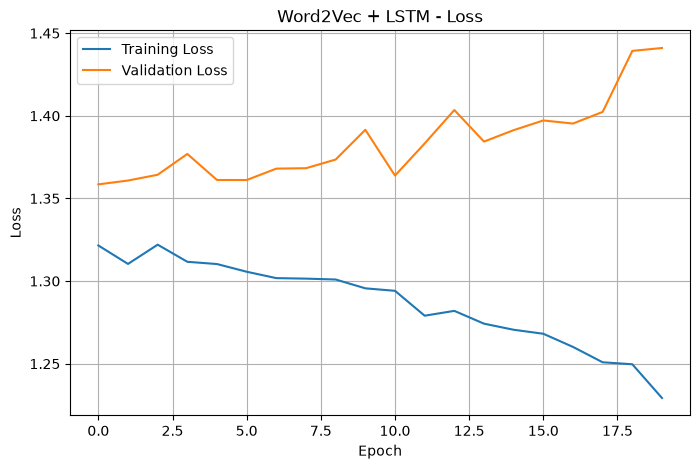

Training history visualization completed!


In [94]:

# ============================================================
# WORD2VEC + LSTM TRAINING HISTORY VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

# Accuracy Graph
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Word2Vec + LSTM - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()


# Loss Graph
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Word2Vec + LSTM - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

print("Training history visualization completed!")


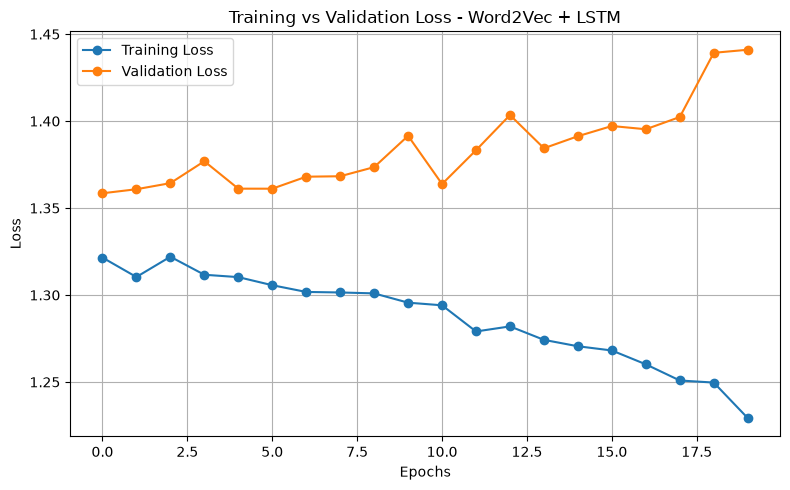

In [95]:

# ============================================================
# TRAINING VS VALIDATION LOSS
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss',
    marker='o'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss',
    marker='o'
)

plt.title('Training vs Validation Loss - Word2Vec + LSTM')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
WORD2VEC + LSTM - TEST SET EVALUATION
Accuracy  : 0.3429
Precision : 0.3353
Recall    : 0.3358
F1-Score  : 0.3326

Classification Report:

              precision    recall  f1-score   support

       anger       0.33      0.24      0.28        83
        fear       0.41      0.42      0.42       113
         joy       0.29      0.29      0.29        77
     sadness       0.32      0.39      0.35        74

    accuracy                           0.34       347
   macro avg       0.34      0.34      0.33       347
weighted avg       0.34      0.34      0.34       347



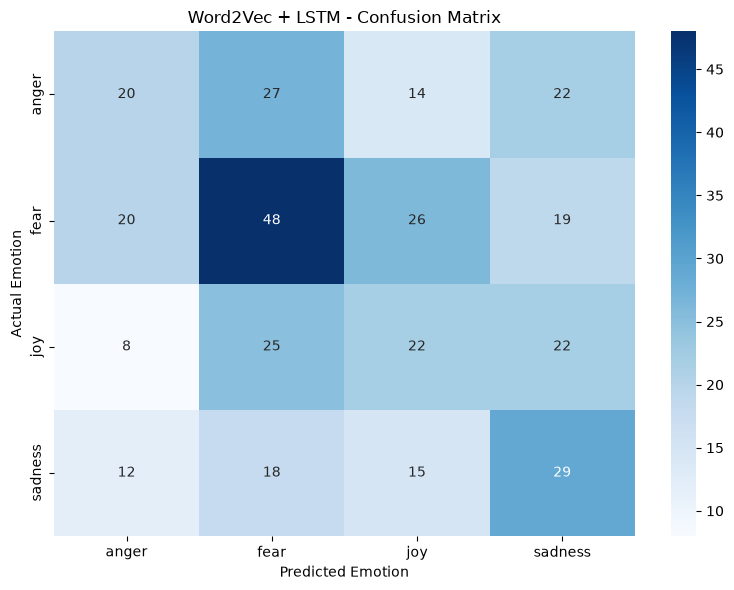

In [96]:

# ============================================================
# TEST SET EVALUATION
# ============================================================

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# Generate predictions on test data
y_test_pred_prob = w2v_lstm_model.predict(X_test_padded)

# Convert probabilities to class labels
y_test_pred = np.argmax(y_test_pred_prob, axis=1)

# Actual test labels
y_test_actual = y_test_encoded

# Calculate evaluation metrics
accuracy = accuracy_score(y_test_actual, y_test_pred)

precision = precision_score(
    y_test_actual, y_test_pred,
    average="macro", zero_division=0
)

recall = recall_score(
    y_test_actual, y_test_pred,
    average="macro", zero_division=0
)

f1 = f1_score(
    y_test_actual, y_test_pred,
    average="macro", zero_division=0
)

# Display evaluation results
print("=" * 60)
print("WORD2VEC + LSTM - TEST SET EVALUATION")
print("=" * 60)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

# Classification Report
print("\nClassification Report:\n")

print(
    classification_report(
        y_test_actual,
        y_test_pred,
        labels=np.arange(num_classes),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# Confusion Matrix
cm = confusion_matrix(
    y_test_actual,
    y_test_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Word2Vec + LSTM - Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.show()


In [97]:

# ============================================================
# PREDICTIONS
# ============================================================

def predict_emotion(sentence):

    # Clean input text
    cleaned_text = clean_text(sentence)

    # Convert text into sequence
    sequence = tokenizer.texts_to_sequences([cleaned_text])

    # Apply padding
    padded_sequence = pad_sequences(
        sequence,
        maxlen=max_len,
        padding='post',
        truncating='post'
    )

    # Predict emotion probabilities
    prediction = w2v_lstm_model.predict(
        padded_sequence,
        verbose=0
    )

    # Get predicted emotion
    predicted_index = np.argmax(prediction, axis=1)[0]
    predicted_emotion = label_encoder.inverse_transform(
        [predicted_index]
    )[0]

    # Calculate confidence
    confidence = np.max(prediction) * 100

    print("Input Sentence:", sentence)
    print("Predicted Emotion:", predicted_emotion)
    print(f"Prediction Confidence: {confidence:.2f}%")

    return predicted_emotion


# Test with a sample sentence
sample_text = "I am feeling very happy today"

predict_emotion(sample_text)


Input Sentence: I am feeling very happy today
Predicted Emotion: joy
Prediction Confidence: 33.20%


'joy'

In [99]:

# ============================================================
# IMPROVED WORD2VEC + LSTM
# ============================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    SpatialDropout1D,
    Bidirectional,
    LSTM,
    Dense,
    Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

# ------------------------------------------------------------
# BUILD IMPROVED MODEL
# ------------------------------------------------------------

improved_w2v_lstm_model = Sequential([

    # Input Layer
    Input(shape=(X_train_padded.shape[1],), dtype="int32"),

    # Word2Vec Embedding Layer
    Embedding(
        input_dim=embedding_matrix_w2v.shape[0],
        output_dim=embedding_matrix_w2v.shape[1],
        weights=[embedding_matrix_w2v],
        trainable=True,
        mask_zero=True
    ),

    # Spatial Dropout
    SpatialDropout1D(0.25),

    # Bidirectional LSTM
    Bidirectional(
        LSTM(
            64,
            dropout=0.25
        )
    ),

    # Dense Layer
    Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    # Dropout
    Dropout(0.4),

    # Output Layer
    Dense(
        num_classes,
        activation="softmax"
    )
])

# ------------------------------------------------------------
# COMPILE MODEL
# ------------------------------------------------------------

improved_w2v_lstm_model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# ------------------------------------------------------------
# MODEL SUMMARY
# ------------------------------------------------------------

improved_w2v_lstm_model.summary()

print("Improved Word2Vec + LSTM model built successfully!")


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 25, 100)        │       766,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_1             │ (None, 25, 100)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        84,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 855,440 (3.26 MB)

 Trainable params: 855,440 (3.26 MB)

 Non-trainable params: 0 (0.00 B)

Improved Word2Vec + LSTM model built successfully!


In [100]:

# ============================================================
# TRAIN IMPROVED WORD2VEC + LSTM
# ============================================================

EPOCHS = 20
BATCH_SIZE = 32

history_improved = improved_w2v_lstm_model.fit(
    X_train_padded,
    y_train_cat,
    validation_data=(X_val_padded, y_val_cat),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
    shuffle=True
)

print("Improved Word2Vec + LSTM Training Completed!")
print(f"Total Epochs Trained: {EPOCHS}")


Epoch 1/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - accuracy: 0.2977 - loss: 1.4314 - val_accuracy: 0.3228 - val_loss: 1.4196
Epoch 2/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.3261 - loss: 1.4214 - val_accuracy: 0.3228 - val_loss: 1.4120
Epoch 3/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.3232 - loss: 1.4109 - val_accuracy: 0.3228 - val_loss: 1.4040
Epoch 4/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.3265 - loss: 1.4025 - val_accuracy: 0.3228 - val_loss: 1.3899
Epoch 5/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.3503 - loss: 1.3749 - val_accuracy: 0.3228 - val_loss: 1.3623
Epoch 6/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.4155 - loss: 1.2943 - val_accuracy: 0.5447 - val_loss: 1.2124
Epoch 7/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.5550 - loss: 1.0943 - val_accuracy: 0.6859 - val_loss: 0.9490
Epoch 8/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.7110 - loss: 0.8165 - val_accuracy: 0.6196 - 

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step
IMPROVED WORD2VEC + LSTM - TEST SET EVALUATION
Accuracy  : 0.8156
Precision : 0.8108
Recall    : 0.8134
F1-Score  : 0.8110

Classification Report:

              precision    recall  f1-score   support

       anger       0.85      0.82      0.83        83
        fear       0.84      0.82      0.83       113
         joy       0.82      0.92      0.87        77
     sadness       0.74      0.69      0.71        74

    accuracy                           0.82       347
   macro avg       0.81      0.81      0.81       347
weighted avg       0.81      0.82      0.81       347



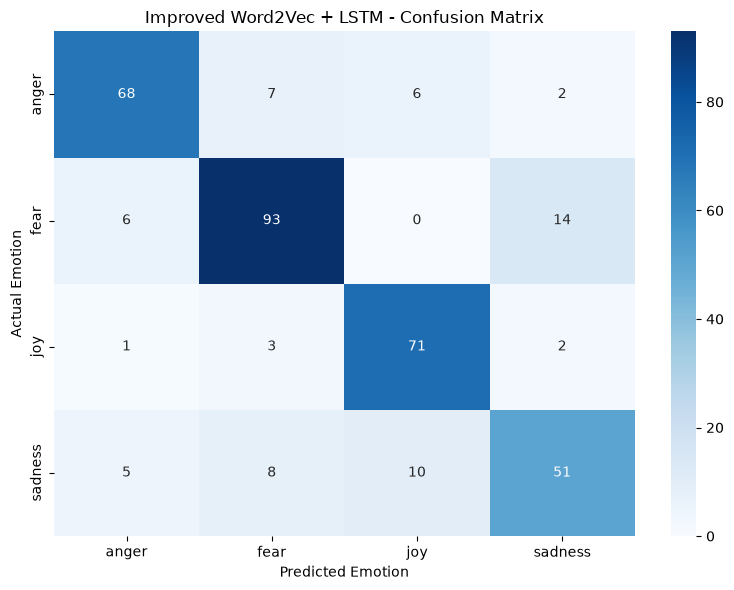

In [101]:

# ============================================================
# IMPROVED WORD2VEC + LSTM - TEST SET EVALUATION
# ============================================================

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# Generate predictions
y_test_pred_prob = improved_w2v_lstm_model.predict(
    X_test_padded,
    verbose=1
)

# Convert probabilities to class labels
y_test_pred = np.argmax(y_test_pred_prob, axis=1)

# Actual test labels
y_test_actual = y_test_encoded

# Calculate evaluation metrics
accuracy = accuracy_score(y_test_actual, y_test_pred)

precision = precision_score(
    y_test_actual,
    y_test_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_test_actual,
    y_test_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_test_actual,
    y_test_pred,
    average="macro",
    zero_division=0
)

# Display results
print("=" * 60)
print("IMPROVED WORD2VEC + LSTM - TEST SET EVALUATION")
print("=" * 60)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

# Classification Report
print("\nClassification Report:\n")

print(
    classification_report(
        y_test_actual,
        y_test_pred,
        labels=np.arange(num_classes),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# Confusion Matrix
cm = confusion_matrix(
    y_test_actual,
    y_test_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Improved Word2Vec + LSTM - Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.show()


In [102]:

# ============================================================
# PREDICTIONS - IMPROVED WORD2VEC + LSTM
# ============================================================

import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences

def predict_emotion(sentence):

    # Clean input sentence
    cleaned_text = clean_text(sentence)

    # Convert text into integer sequences
    sequence = tokenizer.texts_to_sequences([cleaned_text])

    # Apply padding
    padded_sequence = pad_sequences(
        sequence,
        maxlen=X_train_padded.shape[1],
        padding="post",
        truncating="post"
    )

    # Predict using improved model
    probabilities = improved_w2v_lstm_model.predict(
        padded_sequence,
        verbose=0
    )

    # Get predicted class
    predicted_index = np.argmax(probabilities[0])
    predicted_emotion = label_encoder.inverse_transform(
        [predicted_index]
    )[0]

    confidence = probabilities[0][predicted_index] * 100

    print("Input Sentence:", sentence)
    print("Predicted Emotion:", predicted_emotion)
    print(f"Prediction Confidence: {confidence:.2f}%")

    return predicted_emotion


# Test sample sentences
predict_emotion("I am feeling very happy today")
predict_emotion("I am scared about my future")
predict_emotion("I feel lonely and sad")
predict_emotion("I am angry with everyone")


Input Sentence: I am feeling very happy today
Predicted Emotion: joy
Prediction Confidence: 97.83%
Input Sentence: I am scared about my future
Predicted Emotion: anger
Prediction Confidence: 78.94%
Input Sentence: I feel lonely and sad
Predicted Emotion: sadness
Prediction Confidence: 99.23%
Input Sentence: I am angry with everyone
Predicted Emotion: anger
Prediction Confidence: 99.89%


'anger'

In [103]:

# ============================================================
# TRAIN WORD2VEC - CBOW
# ============================================================

from gensim.models import Word2Vec
import numpy as np

# Train Word2Vec using CBOW
word2vec_cbow_model = Word2Vec(
    sentences=train_sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    sg=0,
    epochs=10,
    seed=42
)

print("Word2Vec CBOW Training Completed!")
print("Vocabulary Size:", len(word2vec_cbow_model.wv))
print("Embedding Dimension:", word2vec_cbow_model.wv.vector_size)

# ------------------------------------------------------------
# CREATE CBOW EMBEDDING MATRIX
# ------------------------------------------------------------

embedding_matrix_cbow = np.zeros(
    (vocab_size, embedding_dim),
    dtype=np.float32
)

words_found = 0

for word, index in tokenizer.word_index.items():
    if word in word2vec_cbow_model.wv:
        embedding_matrix_cbow[index] = word2vec_cbow_model.wv[word]
        words_found += 1

print("\nCBOW Embedding Matrix Shape:", embedding_matrix_cbow.shape)
print("Words Found:", words_found)
print("Total Tokenizer Words:", len(tokenizer.word_index))


Word2Vec CBOW Training Completed!
Vocabulary Size: 7665
Embedding Dimension: 100

CBOW Embedding Matrix Shape: (7667, 100)
Words Found: 7665
Total Tokenizer Words: 7666


In [104]:

# ============================================================
# WORD2VEC CBOW + LSTM
# ============================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    SpatialDropout1D,
    Bidirectional,
    LSTM,
    Dense,
    Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

# Build CBOW + LSTM Model
cbow_lstm_model = Sequential([
    Input(shape=(X_train_padded.shape[1],), dtype="int32"),

    Embedding(
        input_dim=embedding_matrix_cbow.shape[0],
        output_dim=embedding_matrix_cbow.shape[1],
        weights=[embedding_matrix_cbow],
        trainable=True,
        mask_zero=True
    ),

    SpatialDropout1D(0.25),

    Bidirectional(
        LSTM(64, dropout=0.25)
    ),

    Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dropout(0.4),

    Dense(num_classes, activation="softmax")
])

# Compile Model
cbow_lstm_model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Display Model Summary
cbow_lstm_model.summary()

print("Word2Vec CBOW + LSTM Model Built Successfully!")


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 25, 100)        │       766,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_2             │ (None, 25, 100)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 128)            │        84,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 855,440 (3.26 MB)

 Trainable params: 855,440 (3.26 MB)

 Non-trainable params: 0 (0.00 B)

Word2Vec CBOW + LSTM Model Built Successfully!


In [105]:

# ============================================================
# TRAIN WORD2VEC CBOW + LSTM
# ============================================================

EPOCHS = 20
BATCH_SIZE = 32

history_cbow = cbow_lstm_model.fit(
    X_train_padded,
    y_train_cat,
    validation_data=(X_val_padded, y_val_cat),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
    shuffle=True
)

print("Word2Vec CBOW + LSTM Training Completed!")
print(f"Total Epochs Trained: {EPOCHS}")


Epoch 1/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.2850 - loss: 1.4462 - val_accuracy: 0.3228 - val_loss: 1.4214
Epoch 2/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.3070 - loss: 1.4260 - val_accuracy: 0.3228 - val_loss: 1.4182
Epoch 3/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.3045 - loss: 1.4268 - val_accuracy: 0.3228 - val_loss: 1.4122
Epoch 4/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.3103 - loss: 1.4159 - val_accuracy: 0.3228 - val_loss: 1.4074
Epoch 5/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.3222 - loss: 1.4031 - val_accuracy: 0.3228 - val_loss: 1.4027
Epoch 6/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.3301 - loss: 1.3897 - val_accuracy: 0.3228 - val_loss: 1.3830
Epoch 7/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.3503 - loss: 1.3539 - val_accuracy: 0.3660 - val_loss: 1.3380
Epoch 8/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.4786 - loss: 1.2286 - val_accuracy: 0.5389 - 

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step
WORD2VEC CBOW + LSTM - TEST SET EVALUATION
Accuracy  : 0.7695
Precision : 0.8027
Recall    : 0.7818
F1-Score  : 0.7762

Classification Report:

              precision    recall  f1-score   support

       anger       0.85      0.72      0.78        83
        fear       0.91      0.68      0.78       113
         joy       0.91      0.83      0.87        77
     sadness       0.55      0.89      0.68        74

    accuracy                           0.77       347
   macro avg       0.80      0.78      0.78       347
weighted avg       0.82      0.77      0.78       347



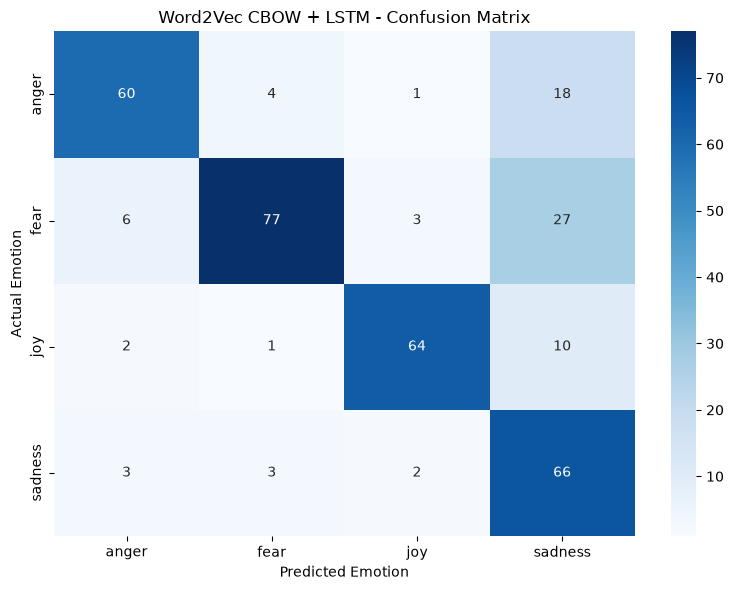

In [106]:

# ============================================================
# WORD2VEC CBOW + LSTM - TEST SET EVALUATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Generate predictions
y_test_pred_prob_cbow = cbow_lstm_model.predict(
    X_test_padded,
    verbose=1
)

# Convert probabilities to class labels
y_test_pred_cbow = np.argmax(
    y_test_pred_prob_cbow,
    axis=1
)

# Actual test labels
y_test_actual = y_test_encoded

# Calculate evaluation metrics
accuracy_cbow = accuracy_score(
    y_test_actual, y_test_pred_cbow
)

precision_cbow = precision_score(
    y_test_actual,
    y_test_pred_cbow,
    average="macro",
    zero_division=0
)

recall_cbow = recall_score(
    y_test_actual,
    y_test_pred_cbow,
    average="macro",
    zero_division=0
)

f1_cbow = f1_score(
    y_test_actual,
    y_test_pred_cbow,
    average="macro",
    zero_division=0
)

# Display evaluation results
print("=" * 60)
print("WORD2VEC CBOW + LSTM - TEST SET EVALUATION")
print("=" * 60)

print(f"Accuracy  : {accuracy_cbow:.4f}")
print(f"Precision : {precision_cbow:.4f}")
print(f"Recall    : {recall_cbow:.4f}")
print(f"F1-Score  : {f1_cbow:.4f}")

# Classification Report
print("\nClassification Report:\n")

print(
    classification_report(
        y_test_actual,
        y_test_pred_cbow,
        labels=np.arange(num_classes),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# Confusion Matrix
cm_cbow = confusion_matrix(
    y_test_actual,
    y_test_pred_cbow,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_cbow,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Word2Vec CBOW + LSTM - Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.show()


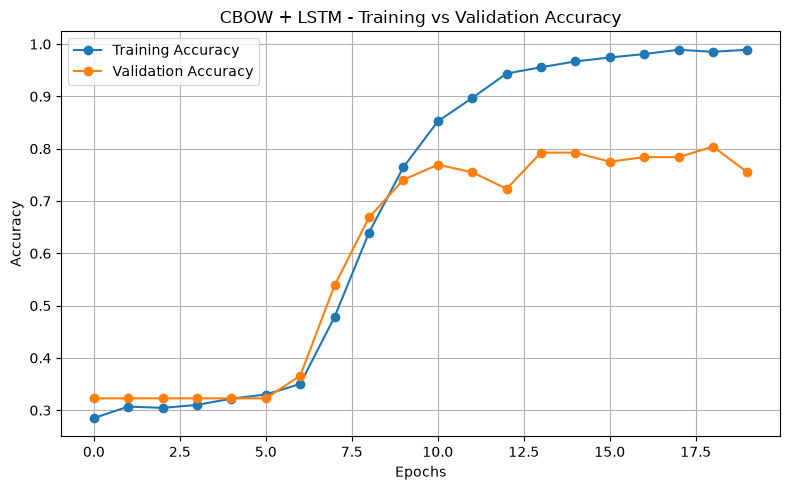

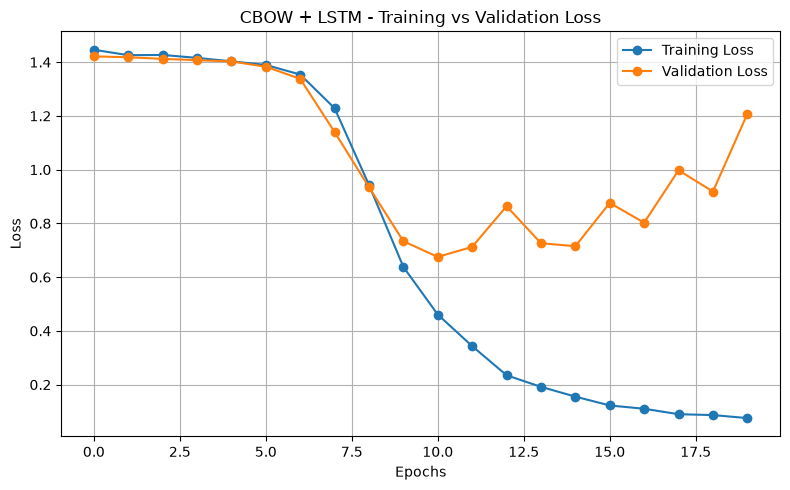

CBOW + LSTM Training History Plotted Successfully!


In [107]:

# ============================================================
# PLOT CBOW + LSTM TRAINING HISTORY
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# TRAINING VS VALIDATION ACCURACY
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    history_cbow.history['accuracy'],
    label='Training Accuracy',
    marker='o'
)

plt.plot(
    history_cbow.history['val_accuracy'],
    label='Validation Accuracy',
    marker='o'
)

plt.title('CBOW + LSTM - Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# TRAINING VS VALIDATION LOSS
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    history_cbow.history['loss'],
    label='Training Loss',
    marker='o'
)

plt.plot(
    history_cbow.history['val_loss'],
    label='Validation Loss',
    marker='o'
)

plt.title('CBOW + LSTM - Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("CBOW + LSTM Training History Plotted Successfully!")


In [109]:

# ============================================================
# TRAIN DOC2VEC - DM AND DBOW
# ============================================================

import numpy as np
from gensim.models.doc2vec import Doc2Vec, TaggedDocument

# ------------------------------------------------------------
# PREPARE TAGGED TRAINING DOCUMENTS
# ------------------------------------------------------------

train_tagged_docs = [
    TaggedDocument(words=words, tags=[f"TRAIN_{i}"])
    for i, words in enumerate(train_sentences)
]

print("Tagged Training Documents:", len(train_tagged_docs))

# ------------------------------------------------------------
# DOC2VEC DM (DISTRIBUTED MEMORY)
# ------------------------------------------------------------

doc2vec_dm_model = Doc2Vec(
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    dm=1,
    epochs=40,
    seed=42
)

doc2vec_dm_model.build_vocab(train_tagged_docs)

doc2vec_dm_model.train(
    train_tagged_docs,
    total_examples=doc2vec_dm_model.corpus_count,
    epochs=40
)

print("Doc2Vec DM Training Completed!")

# ------------------------------------------------------------
# DOC2VEC DBOW (DISTRIBUTED BAG OF WORDS)
# ------------------------------------------------------------

doc2vec_dbow_model = Doc2Vec(
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    dm=0,
    epochs=40,
    seed=42
)

doc2vec_dbow_model.build_vocab(train_tagged_docs)

doc2vec_dbow_model.train(
    train_tagged_docs,
    total_examples=doc2vec_dbow_model.corpus_count,
    epochs=40
)

print("Doc2Vec DBOW Training Completed!")

# ------------------------------------------------------------
# CREATE DM DOCUMENT VECTORS
# ------------------------------------------------------------

X_train_dm = np.vstack([
    doc2vec_dm_model.dv[f"TRAIN_{i}"]
    for i in range(len(train_sentences))
]).astype(np.float32)

X_val_dm = np.vstack([
    doc2vec_dm_model.infer_vector(words, epochs=40)
    for words in val_sentences
]).astype(np.float32)

X_test_dm = np.vstack([
    doc2vec_dm_model.infer_vector(words, epochs=40)
    for words in test_sentences
]).astype(np.float32)

# ------------------------------------------------------------
# CREATE DBOW DOCUMENT VECTORS
# ------------------------------------------------------------

X_train_dbow = np.vstack([
    doc2vec_dbow_model.dv[f"TRAIN_{i}"]
    for i in range(len(train_sentences))
]).astype(np.float32)

X_val_dbow = np.vstack([
    doc2vec_dbow_model.infer_vector(words, epochs=40)
    for words in val_sentences
]).astype(np.float32)

X_test_dbow = np.vstack([
    doc2vec_dbow_model.infer_vector(words, epochs=40)
    for words in test_sentences
]).astype(np.float32)

# ------------------------------------------------------------
# DISPLAY VECTOR SHAPES
# ------------------------------------------------------------

print("\n============================================================")
print("DOC2VEC EMBEDDING SHAPES")
print("============================================================")

print("\nDM:")
print("Training:", X_train_dm.shape)
print("Validation:", X_val_dm.shape)
print("Testing:", X_test_dm.shape)

print("\nDBOW:")
print("Training:", X_train_dbow.shape)
print("Validation:", X_val_dbow.shape)
print("Testing:", X_test_dbow.shape)

print("\nDoc2Vec DM and DBOW embeddings created successfully!")


Tagged Training Documents: 2775
Doc2Vec DM Training Completed!
Doc2Vec DBOW Training Completed!

DOC2VEC EMBEDDING SHAPES

DM:
Training: (2775, 100)
Validation: (347, 100)
Testing: (347, 100)

DBOW:
Training: (2775, 100)
Validation: (347, 100)
Testing: (347, 100)

Doc2Vec DM and DBOW embeddings created successfully!


In [110]:

# ============================================================
# TRAIN DOC2VEC DM AND DBOW CLASSIFIERS
# ============================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

# ------------------------------------------------------------
# DOC2VEC DM CLASSIFIER
# ------------------------------------------------------------

doc2vec_dm_classifier = Sequential([
    Input(shape=(X_train_dm.shape[1],)),

    Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dropout(0.3),

    Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dropout(0.2),

    Dense(num_classes, activation="softmax")
])

doc2vec_dm_classifier.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("DOC2VEC DM CLASSIFIER")
doc2vec_dm_classifier.summary()

# Train DM
history_doc2vec_dm = doc2vec_dm_classifier.fit(
    X_train_dm,
    y_train_cat,
    validation_data=(X_val_dm, y_val_cat),
    epochs=20,
    batch_size=32,
    verbose=1,
    shuffle=True
)

print("Doc2Vec DM Classifier Training Completed!")


# ------------------------------------------------------------
# DOC2VEC DBOW CLASSIFIER
# ------------------------------------------------------------

doc2vec_dbow_classifier = Sequential([
    Input(shape=(X_train_dbow.shape[1],)),

    Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dropout(0.3),

    Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dropout(0.2),

    Dense(num_classes, activation="softmax")
])

doc2vec_dbow_classifier.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nDOC2VEC DBOW CLASSIFIER")
doc2vec_dbow_classifier.summary()

# Train DBOW
history_doc2vec_dbow = doc2vec_dbow_classifier.fit(
    X_train_dbow,
    y_train_cat,
    validation_data=(X_val_dbow, y_val_cat),
    epochs=20,
    batch_size=32,
    verbose=1,
    shuffle=True
)

print("Doc2Vec DBOW Classifier Training Completed!")


DOC2VEC DM CLASSIFIER


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 64)             │         6,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,676 (33.89 KB)

 Trainable params: 8,676 (33.89 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_11 (Dense)                │ (None, 64)             │         6,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,676 (33.89 KB)

 Trainable params: 8,676 (33.89 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.3088 - loss: 1.4735 - val_accuracy: 0.3228 - val_loss: 1.4453
Epoch 2/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3196 - loss: 1.4360 - val_accuracy: 0.3228 - val_loss: 1.4201
Epoch 3/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3236 - loss: 1.4201 - val_accuracy: 0.3228 - val_loss: 1.4095
Epoch 4/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3240 - loss: 1.4094 - val_accuracy: 0.3228 - val_loss: 1.4004
Epoch 5/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3243 - loss: 1.4031 - val_accuracy: 0.3228 - val_loss: 1.3959
Epoch 6/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3240 - loss: 1.3954 - val_accuracy: 0.3228 - val_loss: 1.3881
Epoch 7/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3243 - loss: 1.3935 - val_accuracy: 0.3228 - val_loss: 1.3857
Epoch 8/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3243 - loss: 1.3905 - val_accuracy: 0.3228 - val_loss:

In [111]:

# ============================================================
# DOC2VEC DM AND DBOW - TEST SET EVALUATION
# ============================================================

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# ------------------------------------------------------------
# EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate_doc2vec_model(model, X_test, y_test, model_name):

    # Generate predictions
    y_pred_prob = model.predict(X_test, verbose=0)
    y_pred = np.argmax(y_pred_prob, axis=1)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    print("\n" + "=" * 60)
    print(f"{model_name} - TEST SET EVALUATION")
    print("=" * 60)

    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-Score  : {f1:.4f}")

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            labels=np.arange(num_classes),
            target_names=label_encoder.classes_,
            zero_division=0
        )
    )

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }


# ------------------------------------------------------------
# EVALUATE DOC2VEC DM
# ------------------------------------------------------------

results_dm = evaluate_doc2vec_model(
    doc2vec_dm_classifier,
    X_test_dm,
    y_test_encoded,
    "DOC2VEC DM"
)

# ------------------------------------------------------------
# EVALUATE DOC2VEC DBOW
# ------------------------------------------------------------

results_dbow = evaluate_doc2vec_model(
    doc2vec_dbow_classifier,
    X_test_dbow,
    y_test_encoded,
    "DOC2VEC DBOW"
)

# ------------------------------------------------------------
# COMPARE BOTH MODELS
# ------------------------------------------------------------

import pandas as pd

doc2vec_comparison = pd.DataFrame([
    results_dm,
    results_dbow
])

print("\nDOC2VEC DM VS DBOW COMPARISON")
display(
    doc2vec_comparison.round(4).sort_values(
        by="F1-Score", ascending=False
    )
)



DOC2VEC DM - TEST SET EVALUATION
Accuracy  : 0.3890
Precision : 0.3945
Recall    : 0.3619
F1-Score  : 0.3186

Classification Report:
              precision    recall  f1-score   support

       anger       0.33      0.04      0.07        83
        fear       0.38      0.66      0.49       113
         joy       0.38      0.56      0.45        77
     sadness       0.48      0.19      0.27        74

    accuracy                           0.39       347
   macro avg       0.39      0.36      0.32       347
weighted avg       0.39      0.39      0.33       347


DOC2VEC DBOW - TEST SET EVALUATION
Accuracy  : 0.3256
Precision : 0.0814
Recall    : 0.2500
F1-Score  : 0.1228

Classification Report:
              precision    recall  f1-score   support

       anger       0.00      0.00      0.00        83
        fear       0.33      1.00      0.49       113
         joy       0.00      0.00      0.00        77
     sadness       0.00      0.00      0.00        74

    accuracy           

,Model,Accuracy,Precision,Recall,F1-Score
0,DOC2VEC DM,0.3890,0.3945,0.3619,0.3186
1,DOC2VEC DBOW,0.3256,0.0814,0.2500,0.1228


In [112]:

# ============================================================
# FASTTEXT + LSTM
# ============================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    SpatialDropout1D,
    LSTM,
    Dense,
    Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

# ------------------------------------------------------------
# BUILD FASTTEXT + LSTM MODEL
# ------------------------------------------------------------

fasttext_lstm_model = Sequential([

    # Input Layer
    Input(
        shape=(X_train_padded.shape[1],),
        dtype="int32"
    ),

    # FastText Embedding Layer
    Embedding(
        input_dim=embedding_matrix_fasttext.shape[0],
        output_dim=embedding_matrix_fasttext.shape[1],
        weights=[embedding_matrix_fasttext],
        trainable=True,
        mask_zero=True
    ),

    # Spatial Dropout
    SpatialDropout1D(0.25),

    # LSTM Layer
    LSTM(
        64,
        dropout=0.25
    ),

    # Dense Layer
    Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    # Dropout Layer
    Dropout(0.4),

    # Output Layer
    Dense(num_classes, activation="softmax")
])

# ------------------------------------------------------------
# COMPILE MODEL
# ------------------------------------------------------------

fasttext_lstm_model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

fasttext_lstm_model.summary()

print("FastText + LSTM Model Built Successfully!")


# ------------------------------------------------------------
# TRAIN FASTTEXT + LSTM
# ------------------------------------------------------------

EPOCHS = 20
BATCH_SIZE = 32

history_fasttext = fasttext_lstm_model.fit(
    X_train_padded,
    y_train_cat,
    validation_data=(X_val_padded, y_val_cat),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
    shuffle=True
)

print("FastText + LSTM Training Completed!")
print(f"Total Epochs Trained: {EPOCHS}")


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 25, 100)        │       766,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_3             │ (None, 25, 100)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 811,152 (3.09 MB)

 Trainable params: 811,152 (3.09 MB)

 Non-trainable params: 0 (0.00 B)

FastText + LSTM Model Built Successfully!
Epoch 1/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 8s 27ms/step - accuracy: 0.2998 - loss: 1.4253 - val_accuracy: 0.3228 - val_loss: 1.4069
Epoch 2/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.3193 - loss: 1.4091 - val_accuracy: 0.3228 - val_loss: 1.4030
Epoch 3/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.3247 - loss: 1.4058 - val_accuracy: 0.3228 - val_loss: 1.4018
Epoch 4/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.3214 - loss: 1.3955 - val_accuracy: 0.3228 - val_loss: 1.3890
Epoch 5/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.3290 - loss: 1.3814 - val_accuracy: 0.3228 - val_loss: 1.3720
Epoch 6/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.3712 - loss: 1.3392 - val_accuracy: 0.4294 - val_loss: 1.3147
Epoch 7/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.4735 - loss: 1.2196 - val_accuracy: 0.4784 - val_loss: 1.2506
Epoch 8/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.5377

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step
FASTTEXT + LSTM - TEST SET EVALUATION
Accuracy  : 0.7435
Precision : 0.7380
Recall    : 0.7447
F1-Score  : 0.7372

Classification Report:

              precision    recall  f1-score   support

       anger       0.75      0.73      0.74        83
        fear       0.87      0.73      0.79       113
         joy       0.71      0.88      0.79        77
     sadness       0.62      0.64      0.63        74

    accuracy                           0.74       347
   macro avg       0.74      0.74      0.74       347
weighted avg       0.75      0.74      0.74       347



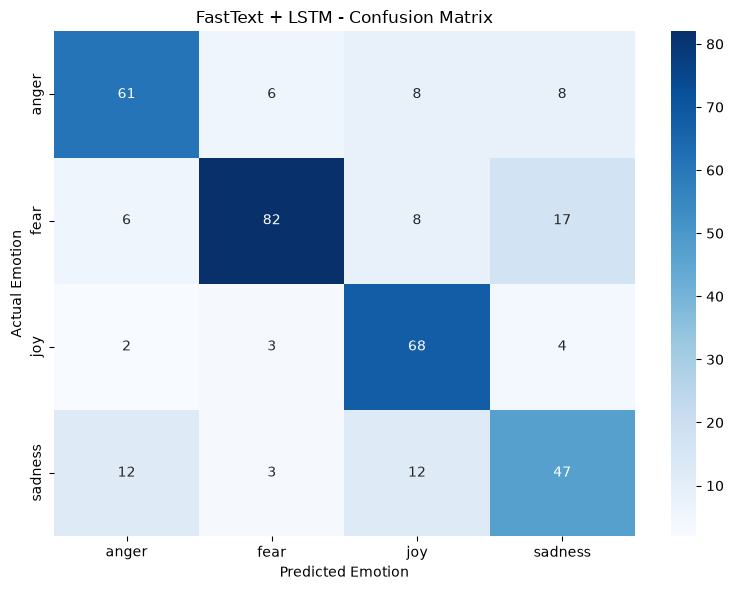

In [113]:

# ============================================================
# FASTTEXT + LSTM - TEST SET EVALUATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# GENERATE TEST PREDICTIONS
# ------------------------------------------------------------

y_test_pred_prob_fasttext = fasttext_lstm_model.predict(
    X_test_padded,
    verbose=1
)

y_test_pred_fasttext = np.argmax(
    y_test_pred_prob_fasttext,
    axis=1
)

y_test_actual = y_test_encoded

# ------------------------------------------------------------
# CALCULATE EVALUATION METRICS
# ------------------------------------------------------------

accuracy_fasttext = accuracy_score(
    y_test_actual, y_test_pred_fasttext
)

precision_fasttext = precision_score(
    y_test_actual,
    y_test_pred_fasttext,
    average="macro",
    zero_division=0
)

recall_fasttext = recall_score(
    y_test_actual,
    y_test_pred_fasttext,
    average="macro",
    zero_division=0
)

f1_fasttext = f1_score(
    y_test_actual,
    y_test_pred_fasttext,
    average="macro",
    zero_division=0
)

print("=" * 60)
print("FASTTEXT + LSTM - TEST SET EVALUATION")
print("=" * 60)

print(f"Accuracy  : {accuracy_fasttext:.4f}")
print(f"Precision : {precision_fasttext:.4f}")
print(f"Recall    : {recall_fasttext:.4f}")
print(f"F1-Score  : {f1_fasttext:.4f}")

# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report:\n")

print(
    classification_report(
        y_test_actual,
        y_test_pred_fasttext,
        labels=np.arange(num_classes),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

cm_fasttext = confusion_matrix(
    y_test_actual,
    y_test_pred_fasttext,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_fasttext,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("FastText + LSTM - Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.show()


In [114]:

# ============================================================
# HYPERPARAMETER TUNING - FASTTEXT + LSTM
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    SpatialDropout1D,
    LSTM,
    Dense,
    Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

from sklearn.metrics import f1_score

# ------------------------------------------------------------
# DEFINE HYPERPARAMETER CONFIGURATIONS
# ------------------------------------------------------------

configs = [
    {
        "lstm_units": 64,
        "spatial_dropout": 0.20,
        "lstm_dropout": 0.20,
        "dense_dropout": 0.30,
        "learning_rate": 0.001,
        "batch_size": 32
    },
    {
        "lstm_units": 128,
        "spatial_dropout": 0.25,
        "lstm_dropout": 0.25,
        "dense_dropout": 0.40,
        "learning_rate": 0.001,
        "batch_size": 32
    },
    {
        "lstm_units": 64,
        "spatial_dropout": 0.30,
        "lstm_dropout": 0.30,
        "dense_dropout": 0.40,
        "learning_rate": 0.0005,
        "batch_size": 32
    },
    {
        "lstm_units": 128,
        "spatial_dropout": 0.20,
        "lstm_dropout": 0.20,
        "dense_dropout": 0.30,
        "learning_rate": 0.0005,
        "batch_size": 64
    }
]

EPOCHS = 20

tuning_results = []
tuned_models = []
tuned_histories = []

# ------------------------------------------------------------
# RUN EACH CONFIGURATION
# ------------------------------------------------------------

for i, config in enumerate(configs, start=1):

    print("\n" + "=" * 60)
    print(f"FASTTEXT + LSTM - EXPERIMENT {i}/{len(configs)}")
    print("=" * 60)

    print("Configuration:", config)

    # Reproducible initialization
    tf.keras.utils.set_random_seed(42)

    # Build model
    tuned_model = Sequential([
        Input(
            shape=(X_train_padded.shape[1],),
            dtype="int32"
        ),

        Embedding(
            input_dim=embedding_matrix_fasttext.shape[0],
            output_dim=embedding_matrix_fasttext.shape[1],
            weights=[embedding_matrix_fasttext],
            trainable=True,
            mask_zero=True
        ),

        SpatialDropout1D(
            config["spatial_dropout"]
        ),

        LSTM(
            config["lstm_units"],
            dropout=config["lstm_dropout"]
        ),

        Dense(
            32,
            activation="relu",
            kernel_regularizer=l2(0.001)
        ),

        Dropout(
            config["dense_dropout"]
        ),

        Dense(
            num_classes,
            activation="softmax"
        )
    ])

    # Compile model
    tuned_model.compile(
        optimizer=Adam(
            learning_rate=config["learning_rate"]
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Train for the specified number of epochs
    # No EarlyStopping or other stopping callbacks
    tuned_history = tuned_model.fit(
        X_train_padded,
        y_train_cat,
        validation_data=(X_val_padded, y_val_cat),
        epochs=EPOCHS,
        batch_size=config["batch_size"],
        verbose=1,
        shuffle=True
    )

    # Validation predictions
    val_probabilities = tuned_model.predict(
        X_val_padded,
        verbose=0
    )

    val_predictions = np.argmax(
        val_probabilities,
        axis=1
    )

    # Validation Macro F1-score
    val_macro_f1 = f1_score(
        y_val_encoded,
        val_predictions,
        average="macro",
        zero_division=0
    )

    # Store results
    tuning_results.append({
        "Experiment": i,
        "LSTM Units": config["lstm_units"],
        "Spatial Dropout": config["spatial_dropout"],
        "LSTM Dropout": config["lstm_dropout"],
        "Dense Dropout": config["dense_dropout"],
        "Learning Rate": config["learning_rate"],
        "Batch Size": config["batch_size"],
        "Train Accuracy": tuned_history.history["accuracy"][-1],
        "Validation Accuracy": tuned_history.history["val_accuracy"][-1],
        "Validation Loss": tuned_history.history["val_loss"][-1],
        "Validation Macro F1": val_macro_f1
    })

    tuned_models.append(tuned_model)
    tuned_histories.append(tuned_history)

    print(f"Experiment {i} Validation Macro F1: {val_macro_f1:.4f}")


# ------------------------------------------------------------
# COMPARE ALL CONFIGURATIONS
# ------------------------------------------------------------

tuning_df = pd.DataFrame(tuning_results)

print("\n" + "=" * 70)
print("FASTTEXT + LSTM HYPERPARAMETER TUNING RESULTS")
print("=" * 70)

display(
    tuning_df.sort_values(
        by="Validation Macro F1",
        ascending=False
    ).round(4).reset_index(drop=True)
)

# ------------------------------------------------------------
# SELECT BEST CONFIGURATION USING VALIDATION MACRO F1
# ------------------------------------------------------------

best_index = int(
    np.argmax(tuning_df["Validation Macro F1"].values)
)

best_fasttext_lstm_model = tuned_models[best_index]
best_fasttext_lstm_history = tuned_histories[best_index]
best_fasttext_lstm_config = configs[best_index]

print("\n" + "=" * 60)
print("BEST FASTTEXT + LSTM CONFIGURATION")
print("=" * 60)

print("Best Configuration:", best_fasttext_lstm_config)
print(
    "Best Validation Macro F1:",
    round(tuning_df.loc[best_index, "Validation Macro F1"], 4)
)

print("Hyperparameter Tuning Completed!")



FASTTEXT + LSTM - EXPERIMENT 1/4
Configuration: {'lstm_units': 64, 'spatial_dropout': 0.2, 'lstm_dropout': 0.2, 'dense_dropout': 0.3, 'learning_rate': 0.001, 'batch_size': 32}
Epoch 1/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 0.3157 - loss: 1.4165 - val_accuracy: 0.3228 - val_loss: 1.4004
Epoch 2/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.3265 - loss: 1.3951 - val_accuracy: 0.3228 - val_loss: 1.3746
Epoch 3/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.3852 - loss: 1.3069 - val_accuracy: 0.4380 - val_loss: 1.2173
Epoch 4/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.5312 - loss: 1.0445 - val_accuracy: 0.5648 - val_loss: 1.1090
Epoch 5/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.6223 - loss: 0.8193 - val_accuracy: 0.6138 - val_loss: 0.9971
Epoch 6/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.7099 - loss: 0.6546 - val_accuracy: 0.6599 - val_loss: 0.9775
Epoch 7/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy

,Experiment,LSTM Units,Spatial Dropout,LSTM Dropout,Dense Dropout,Learning Rate,Batch Size,Train Accuracy,Validation Accuracy,Validation Loss,Validation Macro F1
0,2,128,0.25,0.25,0.4,0.0010,32,0.9899,0.8069,0.9567,0.8033
1,1,64,0.20,0.20,0.3,0.0010,32,0.9924,0.7550,1.1696,0.7519
2,3,64,0.30,0.30,0.4,0.0005,32,0.9106,0.7320,1.0353,0.7265
3,4,128,0.20,0.20,0.3,0.0005,64,0.9582,0.7118,0.9590,0.7108



BEST FASTTEXT + LSTM CONFIGURATION
Best Configuration: {'lstm_units': 128, 'spatial_dropout': 0.25, 'lstm_dropout': 0.25, 'dense_dropout': 0.4, 'learning_rate': 0.001, 'batch_size': 32}
Best Validation Macro F1: 0.8033
Hyperparameter Tuning Completed!


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step
BEST TUNED FASTTEXT + LSTM - TEST EVALUATION
Accuracy  : 0.7752
Precision : 0.7728
Recall    : 0.7586
F1-Score  : 0.7624

Classification Report:

              precision    recall  f1-score   support

       anger       0.81      0.73      0.77        83
        fear       0.79      0.91      0.84       113
         joy       0.74      0.77      0.75        77
     sadness       0.75      0.62      0.68        74

    accuracy                           0.78       347
   macro avg       0.77      0.76      0.76       347
weighted avg       0.78      0.78      0.77       347



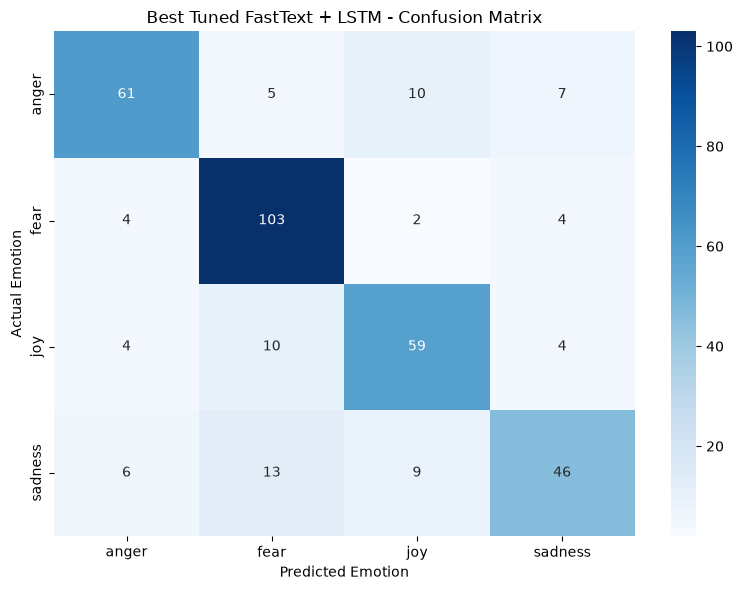

In [115]:

# ============================================================
# BEST TUNED FASTTEXT + LSTM - TEST SET EVALUATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# GENERATE TEST PREDICTIONS
# ------------------------------------------------------------

y_test_prob_tuned = best_fasttext_lstm_model.predict(
    X_test_padded,
    verbose=1
)

y_test_pred_tuned = np.argmax(
    y_test_prob_tuned,
    axis=1
)

y_test_actual = y_test_encoded

# ------------------------------------------------------------
# CALCULATE METRICS
# ------------------------------------------------------------

accuracy_tuned = accuracy_score(
    y_test_actual, y_test_pred_tuned
)

precision_tuned = precision_score(
    y_test_actual,
    y_test_pred_tuned,
    average="macro",
    zero_division=0
)

recall_tuned = recall_score(
    y_test_actual,
    y_test_pred_tuned,
    average="macro",
    zero_division=0
)

f1_tuned = f1_score(
    y_test_actual,
    y_test_pred_tuned,
    average="macro",
    zero_division=0
)

print("=" * 60)
print("BEST TUNED FASTTEXT + LSTM - TEST EVALUATION")
print("=" * 60)

print(f"Accuracy  : {accuracy_tuned:.4f}")
print(f"Precision : {precision_tuned:.4f}")
print(f"Recall    : {recall_tuned:.4f}")
print(f"F1-Score  : {f1_tuned:.4f}")

# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report:\n")

print(
    classification_report(
        y_test_actual,
        y_test_pred_tuned,
        labels=np.arange(num_classes),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

cm_tuned = confusion_matrix(
    y_test_actual,
    y_test_pred_tuned,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Best Tuned FastText + LSTM - Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.show()


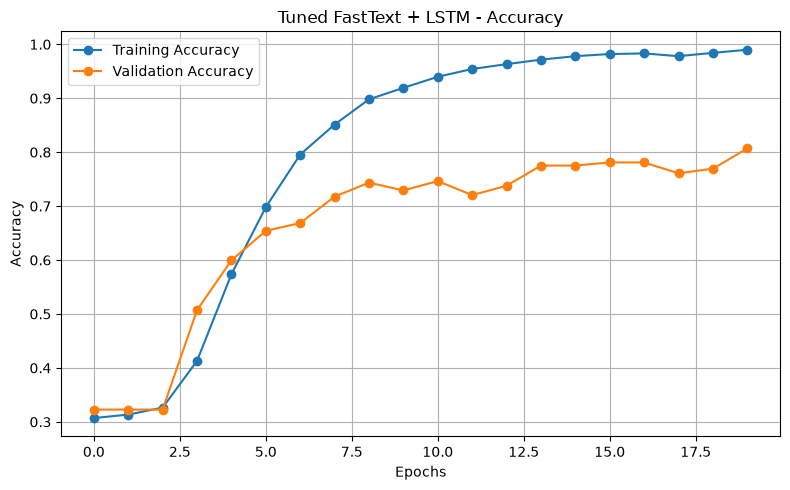

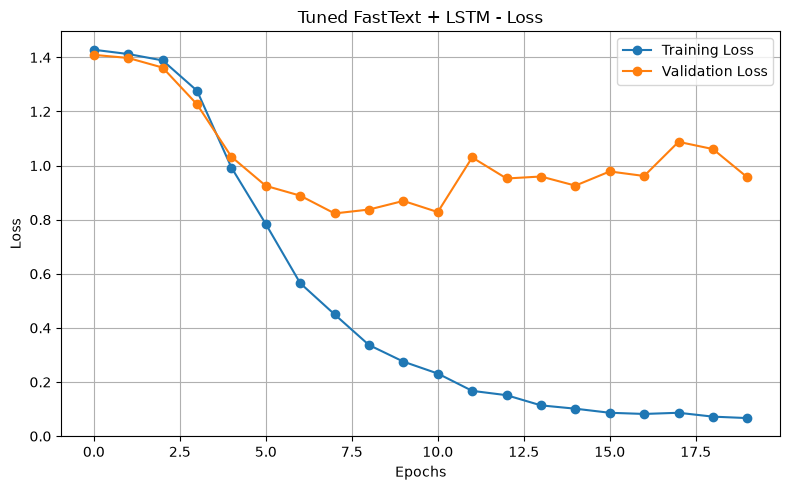

Tuned FastText + LSTM Training History Plotted Successfully!


In [116]:

# ============================================================
# PLOT TUNED FASTTEXT + LSTM TRAINING HISTORY
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# TRAINING VS VALIDATION ACCURACY
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    best_fasttext_lstm_history.history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    best_fasttext_lstm_history.history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("Tuned FastText + LSTM - Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# TRAINING VS VALIDATION LOSS
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    best_fasttext_lstm_history.history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    best_fasttext_lstm_history.history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("Tuned FastText + LSTM - Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("Tuned FastText + LSTM Training History Plotted Successfully!")


In [117]:

# ============================================================
# FASTTEXT + BILSTM
# ============================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    SpatialDropout1D,
    Bidirectional,
    LSTM,
    Dense,
    Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

# ------------------------------------------------------------
# BUILD FASTTEXT + BILSTM MODEL
# ------------------------------------------------------------

fasttext_bilstm_model = Sequential([

    Input(
        shape=(X_train_padded.shape[1],),
        dtype="int32"
    ),

    # FastText Embedding
    Embedding(
        input_dim=embedding_matrix_fasttext.shape[0],
        output_dim=embedding_matrix_fasttext.shape[1],
        weights=[embedding_matrix_fasttext],
        trainable=True,
        mask_zero=True
    ),

    # Spatial Dropout
    SpatialDropout1D(0.25),

    # Bidirectional LSTM
    Bidirectional(
        LSTM(128, dropout=0.25)
    ),

    # Dense Layer
    Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    # Dropout
    Dropout(0.4),

    # Output Layer
    Dense(num_classes, activation="softmax")
])

# ------------------------------------------------------------
# COMPILE MODEL
# ------------------------------------------------------------

fasttext_bilstm_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

fasttext_bilstm_model.summary()

print("FastText + BiLSTM Model Built Successfully!")

# ------------------------------------------------------------
# TRAIN MODEL
# ------------------------------------------------------------

EPOCHS = 20
BATCH_SIZE = 32

history_fasttext_bilstm = fasttext_bilstm_model.fit(
    X_train_padded,
    y_train_cat,
    validation_data=(X_val_padded, y_val_cat),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
    shuffle=True
)

print("FastText + BiLSTM Training Completed!")
print(f"Total Epochs Trained: {EPOCHS}")


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_9 (Embedding)         │ (None, 25, 100)        │       766,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_8             │ (None, 25, 100)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 256)            │       234,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,009,552 (3.85 MB)

 Trainable params: 1,009,552 (3.85 MB)

 Non-trainable params: 0 (0.00 B)

FastText + BiLSTM Model Built Successfully!
Epoch 1/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 13s 55ms/step - accuracy: 0.3186 - loss: 1.4350 - val_accuracy: 0.3228 - val_loss: 1.4172
Epoch 2/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.3182 - loss: 1.4192 - val_accuracy: 0.3228 - val_loss: 1.4011
Epoch 3/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.3232 - loss: 1.3962 - val_accuracy: 0.3228 - val_loss: 1.3814
Epoch 4/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.3477 - loss: 1.3365 - val_accuracy: 0.3746 - val_loss: 1.3137
Epoch 5/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.4836 - loss: 1.1430 - val_accuracy: 0.5937 - val_loss: 1.0434
Epoch 6/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.6515 - loss: 0.8551 - val_accuracy: 0.6686 - val_loss: 0.8921
Epoch 7/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.7813 - loss: 0.5947 - val_accuracy: 0.7406 - val_loss: 0.6862
Epoch 8/20
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.8

11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 91ms/step
FASTTEXT + BILSTM - TEST SET EVALUATION
Accuracy  : 0.8069
Precision : 0.8049
Recall    : 0.8051
F1-Score  : 0.8010

Classification Report:

              precision    recall  f1-score   support

       anger       0.82      0.76      0.79        83
        fear       0.89      0.82      0.85       113
         joy       0.72      0.92      0.81        77
     sadness       0.79      0.72      0.75        74

    accuracy                           0.81       347
   macro avg       0.80      0.81      0.80       347
weighted avg       0.81      0.81      0.81       347



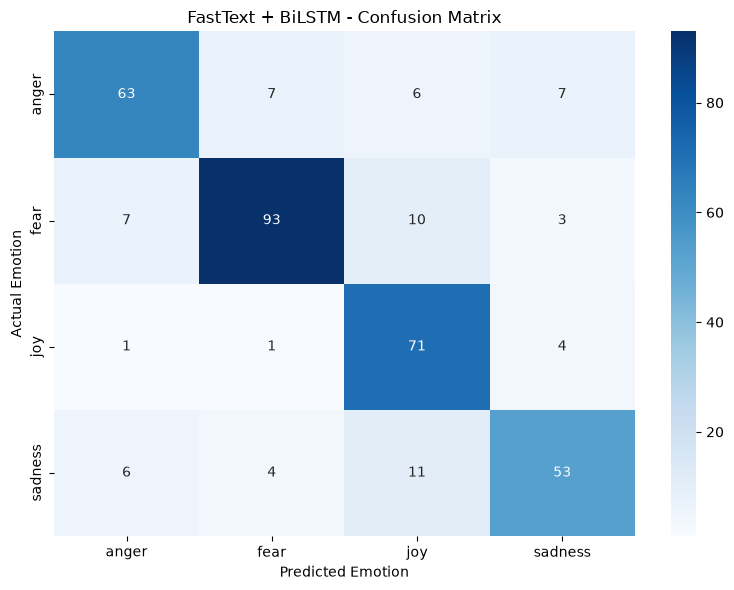

In [118]:

# ============================================================
# FASTTEXT + BILSTM - TEST SET EVALUATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# GENERATE TEST PREDICTIONS
# ------------------------------------------------------------

y_test_prob_fasttext_bilstm = fasttext_bilstm_model.predict(
    X_test_padded,
    verbose=1
)

y_test_pred_fasttext_bilstm = np.argmax(
    y_test_prob_fasttext_bilstm,
    axis=1
)

y_test_actual = y_test_encoded

# ------------------------------------------------------------
# CALCULATE EVALUATION METRICS
# ------------------------------------------------------------

accuracy_fasttext_bilstm = accuracy_score(
    y_test_actual,
    y_test_pred_fasttext_bilstm
)

precision_fasttext_bilstm = precision_score(
    y_test_actual,
    y_test_pred_fasttext_bilstm,
    average="macro",
    zero_division=0
)

recall_fasttext_bilstm = recall_score(
    y_test_actual,
    y_test_pred_fasttext_bilstm,
    average="macro",
    zero_division=0
)

f1_fasttext_bilstm = f1_score(
    y_test_actual,
    y_test_pred_fasttext_bilstm,
    average="macro",
    zero_division=0
)

# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 60)
print("FASTTEXT + BILSTM - TEST SET EVALUATION")
print("=" * 60)

print(f"Accuracy  : {accuracy_fasttext_bilstm:.4f}")
print(f"Precision : {precision_fasttext_bilstm:.4f}")
print(f"Recall    : {recall_fasttext_bilstm:.4f}")
print(f"F1-Score  : {f1_fasttext_bilstm:.4f}")

# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report:\n")

print(
    classification_report(
        y_test_actual,
        y_test_pred_fasttext_bilstm,
        labels=np.arange(num_classes),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

cm_fasttext_bilstm = confusion_matrix(
    y_test_actual,
    y_test_pred_fasttext_bilstm,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_fasttext_bilstm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("FastText + BiLSTM - Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.show()


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
FASTTEXT + BILSTM - TEST SET EVALUATION
Accuracy  : 0.8069
Precision : 0.8049
Recall    : 0.8051
F1-Score  : 0.8010

Classification Report:

              precision    recall  f1-score   support

       anger       0.82      0.76      0.79        83
        fear       0.89      0.82      0.85       113
         joy       0.72      0.92      0.81        77
     sadness       0.79      0.72      0.75        74

    accuracy                           0.81       347
   macro avg       0.80      0.81      0.80       347
weighted avg       0.81      0.81      0.81       347



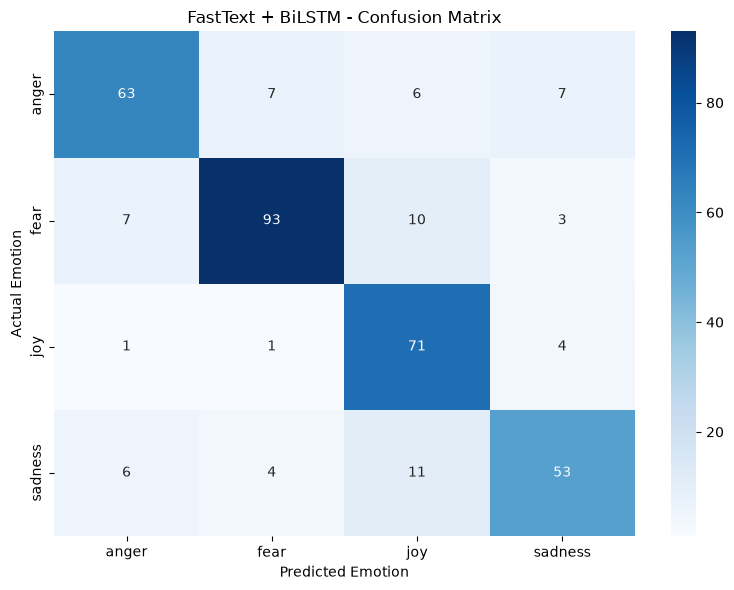

In [121]:

# ============================================================
# FASTTEXT + BILSTM - TEST SET EVALUATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Generate test predictions
y_test_prob_fasttext_bilstm = fasttext_bilstm_model.predict(
    X_test_padded,
    verbose=1
)

y_test_pred_fasttext_bilstm = np.argmax(
    y_test_prob_fasttext_bilstm,
    axis=1
)

y_test_actual = y_test_encoded

# Calculate metrics
accuracy = accuracy_score(
    y_test_actual,
    y_test_pred_fasttext_bilstm
)

precision = precision_score(
    y_test_actual,
    y_test_pred_fasttext_bilstm,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_test_actual,
    y_test_pred_fasttext_bilstm,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_test_actual,
    y_test_pred_fasttext_bilstm,
    average="macro",
    zero_division=0
)

print("=" * 60)
print("FASTTEXT + BILSTM - TEST SET EVALUATION")
print("=" * 60)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

# Classification Report
print("\nClassification Report:\n")

print(
    classification_report(
        y_test_actual,
        y_test_pred_fasttext_bilstm,
        labels=np.arange(num_classes),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# Confusion Matrix
cm_fasttext_bilstm = confusion_matrix(
    y_test_actual,
    y_test_pred_fasttext_bilstm,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_fasttext_bilstm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("FastText + BiLSTM - Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.show()


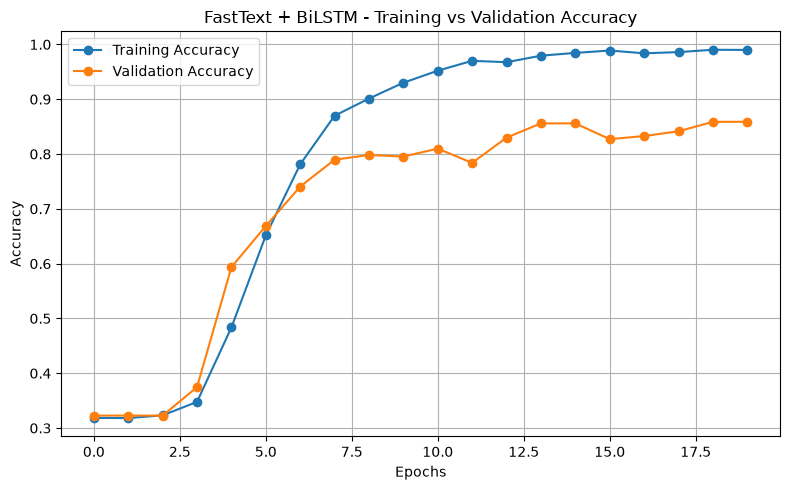

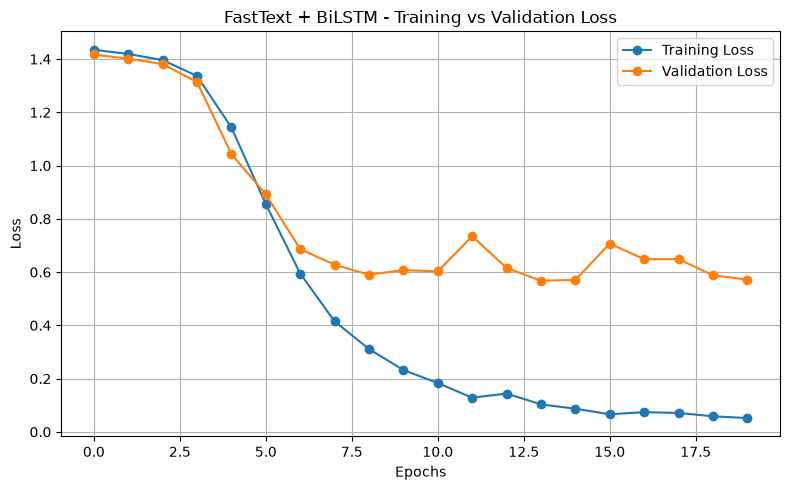

FastText + BiLSTM Training History Plotted Successfully!


In [122]:

# ============================================================
# PLOT FASTTEXT + BILSTM TRAINING HISTORY
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# TRAINING VS VALIDATION ACCURACY
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    history_fasttext_bilstm.history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    history_fasttext_bilstm.history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("FastText + BiLSTM - Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# TRAINING VS VALIDATION LOSS
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    history_fasttext_bilstm.history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    history_fasttext_bilstm.history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("FastText + BiLSTM - Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("FastText + BiLSTM Training History Plotted Successfully!")


In [123]:

# ============================================================
# CONTINUE FASTTEXT + BILSTM TRAINING - 30 EPOCHS
# ============================================================

EPOCHS = 30
BATCH_SIZE = 32

history_fasttext_bilstm_30 = fasttext_bilstm_model.fit(
    X_train_padded,
    y_train_cat,
    validation_data=(X_val_padded, y_val_cat),
    initial_epoch=20,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
    shuffle=True
)

print("FastText + BiLSTM Training Completed!")
print("Total Epochs: 30")


Epoch 21/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.9942 - loss: 0.0401 - val_accuracy: 0.8588 - val_loss: 0.6548
Epoch 22/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.9960 - loss: 0.0356 - val_accuracy: 0.8703 - val_loss: 0.5279
Epoch 23/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.9917 - loss: 0.0406 - val_accuracy: 0.8703 - val_loss: 0.5406
Epoch 24/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.9888 - loss: 0.0546 - val_accuracy: 0.8386 - val_loss: 0.6589
Epoch 25/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.9932 - loss: 0.0397 - val_accuracy: 0.8674 - val_loss: 0.5577
Epoch 26/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.9950 - loss: 0.0394 - val_accuracy: 0.8876 - val_loss: 0.5071
Epoch 27/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.9964 - loss: 0.0274 - val_accuracy: 0.8761 - val_loss: 0.6171
Epoch 28/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.9939 - loss: 0.0363 - val_accuracy: 0.

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
FASTTEXT + BILSTM - TEST SET EVALUATION
Accuracy  : 0.8444
Precision : 0.8424
Recall    : 0.8375
F1-Score  : 0.8371

Classification Report:

              precision    recall  f1-score   support

       anger       0.82      0.78      0.80        83
        fear       0.87      0.90      0.89       113
         joy       0.82      0.95      0.88        77
     sadness       0.85      0.72      0.78        74

    accuracy                           0.84       347
   macro avg       0.84      0.84      0.84       347
weighted avg       0.85      0.84      0.84       347



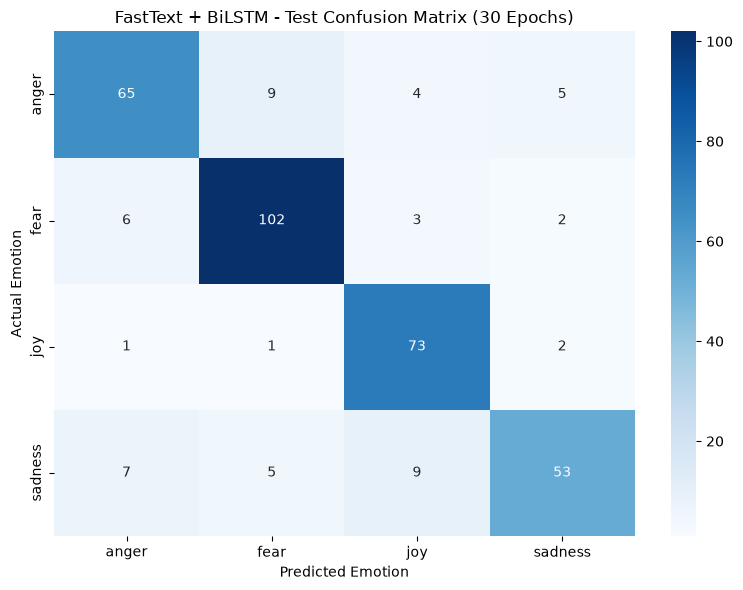

In [124]:

# ============================================================
# FASTTEXT + BILSTM - TEST SET EVALUATION (30 EPOCHS)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# GENERATE TEST PREDICTIONS
# ------------------------------------------------------------

y_test_prob_fasttext_bilstm_30 = (
    fasttext_bilstm_model.predict(
        X_test_padded,
        verbose=1
    )
)

y_test_pred_fasttext_bilstm_30 = np.argmax(
    y_test_prob_fasttext_bilstm_30,
    axis=1
)

y_test_actual = y_test_encoded

# ------------------------------------------------------------
# CALCULATE EVALUATION METRICS
# ------------------------------------------------------------

accuracy_30 = accuracy_score(
    y_test_actual,
    y_test_pred_fasttext_bilstm_30
)

precision_30 = precision_score(
    y_test_actual,
    y_test_pred_fasttext_bilstm_30,
    average="macro",
    zero_division=0
)

recall_30 = recall_score(
    y_test_actual,
    y_test_pred_fasttext_bilstm_30,
    average="macro",
    zero_division=0
)

f1_30 = f1_score(
    y_test_actual,
    y_test_pred_fasttext_bilstm_30,
    average="macro",
    zero_division=0
)

print("=" * 60)
print("FASTTEXT + BILSTM - TEST SET EVALUATION")
print("=" * 60)

print(f"Accuracy  : {accuracy_30:.4f}")
print(f"Precision : {precision_30:.4f}")
print(f"Recall    : {recall_30:.4f}")
print(f"F1-Score  : {f1_30:.4f}")

# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report:\n")

print(
    classification_report(
        y_test_actual,
        y_test_pred_fasttext_bilstm_30,
        labels=np.arange(num_classes),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

cm_fasttext_bilstm_30 = confusion_matrix(
    y_test_actual,
    y_test_pred_fasttext_bilstm_30,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_fasttext_bilstm_30,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("FastText + BiLSTM - Test Confusion Matrix (30 Epochs)")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.show()


In [125]:

# ============================================================
# FASTTEXT + BILSTM - CONTINUE TRAINING UP TO 40 EPOCHS
# ============================================================

EPOCHS = 40
BATCH_SIZE = 32

history_fasttext_bilstm_40 = fasttext_bilstm_model.fit(
    X_train_padded,
    y_train_cat,
    validation_data=(X_val_padded, y_val_cat),
    initial_epoch=30,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
    shuffle=True
)

print("FastText + BiLSTM Training Completed!")
print("Total Epochs: 40")


Epoch 31/40
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.9953 - loss: 0.0281 - val_accuracy: 0.8790 - val_loss: 0.5324
Epoch 32/40
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.9957 - loss: 0.0250 - val_accuracy: 0.8876 - val_loss: 0.5346
Epoch 33/40
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.9978 - loss: 0.0201 - val_accuracy: 0.8761 - val_loss: 0.6247
Epoch 34/40
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.9986 - loss: 0.0192 - val_accuracy: 0.8790 - val_loss: 0.6058
Epoch 35/40
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.9968 - loss: 0.0201 - val_accuracy: 0.8790 - val_loss: 0.5456
Epoch 36/40
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.9989 - loss: 0.0175 - val_accuracy: 0.8818 - val_loss: 0.5194
Epoch 37/40
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.9946 - loss: 0.0308 - val_accuracy: 0.8790 - val_loss: 0.5922
Epoch 38/40
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.9982 - loss: 0.0192 - val_accuracy: 0.

In [126]:

# ============================================================
# FASTTEXT + BILSTM - CONTINUE TRAINING UP TO 50 EPOCHS
# ============================================================

EPOCHS = 50
BATCH_SIZE = 32

history_fasttext_bilstm_50 = fasttext_bilstm_model.fit(
    X_train_padded,
    y_train_cat,
    validation_data=(X_val_padded, y_val_cat),
    initial_epoch=40,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
    shuffle=True
)

print("FastText + BiLSTM Training Completed!")
print("Total Epochs: 50")


Epoch 41/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.9950 - loss: 0.0312 - val_accuracy: 0.8703 - val_loss: 0.5315
Epoch 42/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.9993 - loss: 0.0178 - val_accuracy: 0.8588 - val_loss: 0.5808
Epoch 43/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.9968 - loss: 0.0255 - val_accuracy: 0.8876 - val_loss: 0.5240
Epoch 44/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.9975 - loss: 0.0172 - val_accuracy: 0.8818 - val_loss: 0.5625
Epoch 45/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.9978 - loss: 0.0151 - val_accuracy: 0.8934 - val_loss: 0.5672
Epoch 46/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.9996 - loss: 0.0130 - val_accuracy: 0.8761 - val_loss: 0.5931
Epoch 47/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.9996 - loss: 0.0108 - val_accuracy: 0.8790 - val_loss: 0.6545
Epoch 48/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.9975 - loss: 0.0149 - val_accuracy: 0.

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
FASTTEXT + BILSTM - TEST EVALUATION (50 EPOCHS)
Accuracy  : 0.8386
Precision : 0.8407
Recall    : 0.8421
F1-Score  : 0.8371

Classification Report:

              precision    recall  f1-score   support

       anger       0.82      0.83      0.83        83
        fear       0.91      0.81      0.85       113
         joy       0.75      0.95      0.84        77
     sadness       0.88      0.78      0.83        74

    accuracy                           0.84       347
   macro avg       0.84      0.84      0.84       347
weighted avg       0.85      0.84      0.84       347



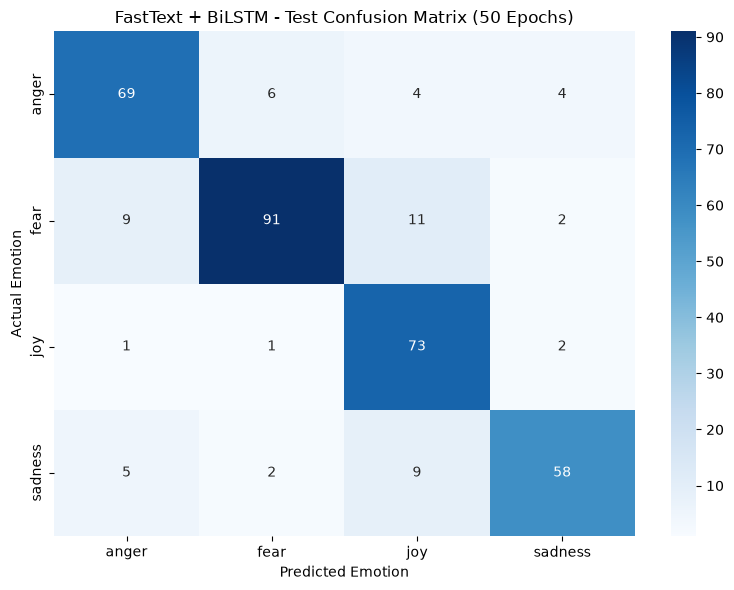

In [127]:

# ============================================================
# FASTTEXT + BILSTM - TEST SET EVALUATION (50 EPOCHS)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Generate test predictions
y_test_prob_fasttext_bilstm_50 = (
    fasttext_bilstm_model.predict(
        X_test_padded,
        verbose=1
    )
)

y_test_pred_fasttext_bilstm_50 = np.argmax(
    y_test_prob_fasttext_bilstm_50,
    axis=1
)

y_test_actual = y_test_encoded

# Calculate metrics
accuracy_50 = accuracy_score(
    y_test_actual, y_test_pred_fasttext_bilstm_50
)

precision_50 = precision_score(
    y_test_actual,
    y_test_pred_fasttext_bilstm_50,
    average="macro",
    zero_division=0
)

recall_50 = recall_score(
    y_test_actual,
    y_test_pred_fasttext_bilstm_50,
    average="macro",
    zero_division=0
)

f1_50 = f1_score(
    y_test_actual,
    y_test_pred_fasttext_bilstm_50,
    average="macro",
    zero_division=0
)

print("=" * 60)
print("FASTTEXT + BILSTM - TEST EVALUATION (50 EPOCHS)")
print("=" * 60)

print(f"Accuracy  : {accuracy_50:.4f}")
print(f"Precision : {precision_50:.4f}")
print(f"Recall    : {recall_50:.4f}")
print(f"F1-Score  : {f1_50:.4f}")

# Classification report
print("\nClassification Report:\n")

print(
    classification_report(
        y_test_actual,
        y_test_pred_fasttext_bilstm_50,
        labels=np.arange(num_classes),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# Confusion Matrix
cm_50 = confusion_matrix(
    y_test_actual,
    y_test_pred_fasttext_bilstm_50,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_50,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("FastText + BiLSTM - Test Confusion Matrix (50 Epochs)")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.show()


In [128]:

# ============================================================
# FASTTEXT + GRU
# ============================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    SpatialDropout1D,
    GRU,
    Dense,
    Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

# ------------------------------------------------------------
# BUILD FASTTEXT + GRU MODEL
# ------------------------------------------------------------

fasttext_gru_model = Sequential([
    Input(
        shape=(X_train_padded.shape[1],),
        dtype="int32"
    ),

    # FastText Embedding Layer
    Embedding(
        input_dim=embedding_matrix_fasttext.shape[0],
        output_dim=embedding_matrix_fasttext.shape[1],
        weights=[embedding_matrix_fasttext],
        trainable=True,
        mask_zero=True
    ),

    SpatialDropout1D(0.25),

    # GRU Layer
    GRU(
        64,
        dropout=0.25
    ),

    Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dropout(0.4),

    # Output Layer
    Dense(num_classes, activation="softmax")
])

# ------------------------------------------------------------
# COMPILE MODEL
# ------------------------------------------------------------

fasttext_gru_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

fasttext_gru_model.summary()

print("FastText + GRU Model Built Successfully!")

# ------------------------------------------------------------
# TRAIN FASTTEXT + GRU
# ------------------------------------------------------------

EPOCHS = 30
BATCH_SIZE = 32

history_fasttext_gru = fasttext_gru_model.fit(
    X_train_padded,
    y_train_cat,
    validation_data=(X_val_padded, y_val_cat),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
    shuffle=True
)

print("FastText + GRU Training Completed!")
print(f"Total Epochs Trained: {EPOCHS}")


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_10 (Embedding)        │ (None, 25, 100)        │       766,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_9             │ (None, 25, 100)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        31,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 800,784 (3.05 MB)

 Trainable params: 800,784 (3.05 MB)

 Non-trainable params: 0 (0.00 B)

FastText + GRU Model Built Successfully!
Epoch 1/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 8s 29ms/step - accuracy: 0.2883 - loss: 1.4249 - val_accuracy: 0.3228 - val_loss: 1.4040
Epoch 2/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.3196 - loss: 1.4065 - val_accuracy: 0.3228 - val_loss: 1.3912
Epoch 3/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.3355 - loss: 1.3781 - val_accuracy: 0.3746 - val_loss: 1.3543
Epoch 4/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.4587 - loss: 1.2589 - val_accuracy: 0.4553 - val_loss: 1.1997
Epoch 5/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.6123 - loss: 0.9819 - val_accuracy: 0.5908 - val_loss: 1.0355
Epoch 6/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.7668 - loss: 0.6830 - val_accuracy: 0.6138 - val_loss: 1.0150
Epoch 7/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.8386 - loss: 0.5239 - val_accuracy: 0.6196 - val_loss: 1.0286
Epoch 8/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.8789 

In [129]:

# ============================================================
# FASTTEXT + BIGRU
# ============================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    SpatialDropout1D,
    GRU,
    Bidirectional,
    Dense,
    Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

# ------------------------------------------------------------
# BUILD FASTTEXT + BIGRU MODEL
# ------------------------------------------------------------

fasttext_bigru_model = Sequential([
    Input(
        shape=(X_train_padded.shape[1],),
        dtype="int32"
    ),

    # FastText Embedding Layer
    Embedding(
        input_dim=embedding_matrix_fasttext.shape[0],
        output_dim=embedding_matrix_fasttext.shape[1],
        weights=[embedding_matrix_fasttext],
        trainable=True,
        mask_zero=True
    ),

    SpatialDropout1D(0.25),

    # Bidirectional GRU Layer
    Bidirectional(
        GRU(64, dropout=0.25)
    ),

    Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dropout(0.4),

    # Output Layer
    Dense(num_classes, activation="softmax")
])

# ------------------------------------------------------------
# COMPILE MODEL
# ------------------------------------------------------------

fasttext_bigru_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

fasttext_bigru_model.summary()

print("FastText + BiGRU Model Built Successfully!")

# ------------------------------------------------------------
# TRAIN FASTTEXT + BIGRU
# ------------------------------------------------------------

EPOCHS = 30
BATCH_SIZE = 32

history_fasttext_bigru = fasttext_bigru_model.fit(
    X_train_padded,
    y_train_cat,
    validation_data=(X_val_padded, y_val_cat),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
    shuffle=True
)

print("FastText + BiGRU Training Completed!")
print(f"Total Epochs Trained: {EPOCHS}")


Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_11 (Embedding)        │ (None, 25, 100)        │       766,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_10            │ (None, 25, 100)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ (None, 128)            │        63,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 834,704 (3.18 MB)

 Trainable params: 834,704 (3.18 MB)

 Non-trainable params: 0 (0.00 B)

FastText + BiGRU Model Built Successfully!
Epoch 1/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.2984 - loss: 1.4359 - val_accuracy: 0.3228 - val_loss: 1.4106
Epoch 2/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.3225 - loss: 1.4139 - val_accuracy: 0.3228 - val_loss: 1.4016
Epoch 3/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.3247 - loss: 1.3920 - val_accuracy: 0.3228 - val_loss: 1.3715
Epoch 4/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.4018 - loss: 1.2994 - val_accuracy: 0.4928 - val_loss: 1.2136
Epoch 5/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.5481 - loss: 1.0571 - val_accuracy: 0.5447 - val_loss: 1.0987
Epoch 6/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.6760 - loss: 0.8246 - val_accuracy: 0.5793 - val_loss: 1.0284
Epoch 7/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.7658 - loss: 0.6257 - val_accuracy: 0.6282 - val_loss: 1.0045
Epoch 8/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.85


FastText + GRU - TEST SET EVALUATION
Accuracy  : 0.7406
Precision : 0.7421
Recall    : 0.7419
F1-Score  : 0.7378

Classification Report:

              precision    recall  f1-score   support

       anger       0.72      0.88      0.79        83
        fear       0.81      0.70      0.75       113
         joy       0.84      0.74      0.79        77
     sadness       0.60      0.65      0.62        74

    accuracy                           0.74       347
   macro avg       0.74      0.74      0.74       347
weighted avg       0.75      0.74      0.74       347



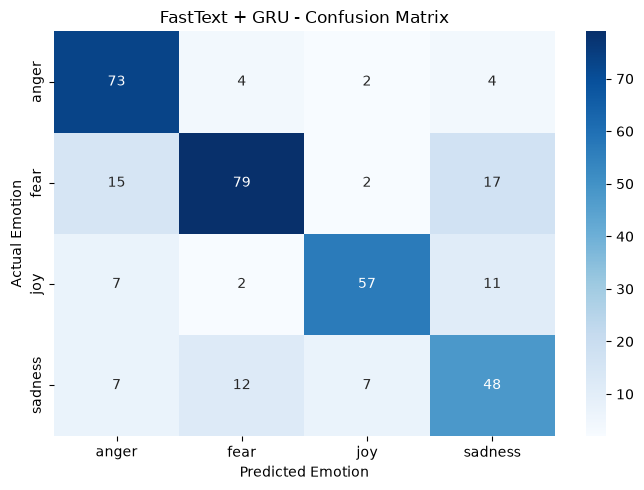


FastText + BiGRU - TEST SET EVALUATION
Accuracy  : 0.7781
Precision : 0.7743
Recall    : 0.7685
F1-Score  : 0.7695

Classification Report:

              precision    recall  f1-score   support

       anger       0.79      0.70      0.74        83
        fear       0.87      0.87      0.87       113
         joy       0.84      0.81      0.82        77
     sadness       0.60      0.70      0.65        74

    accuracy                           0.78       347
   macro avg       0.77      0.77      0.77       347
weighted avg       0.79      0.78      0.78       347



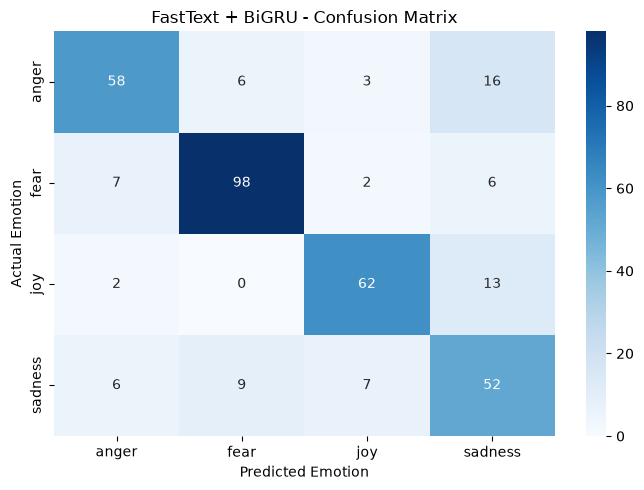


FASTTEXT + GRU VS BIGRU COMPARISON


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,FastText + BiGRU,0.7781,0.7743,0.7685,0.7695
1,FastText + GRU,0.7406,0.7421,0.7419,0.7378


In [130]:

# ============================================================
# FASTTEXT + GRU AND BIGRU - TEST SET EVALUATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate_sequence_model(model, X_test, y_test, model_name):

    # Generate predictions
    y_prob = model.predict(X_test, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    print("\n" + "=" * 60)
    print(f"{model_name} - TEST SET EVALUATION")
    print("=" * 60)

    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-Score  : {f1:.4f}")

    print("\nClassification Report:\n")

    print(
        classification_report(
            y_test,
            y_pred,
            labels=np.arange(num_classes),
            target_names=label_encoder.classes_,
            zero_division=0
        )
    )

    # Confusion Matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(num_classes)
    )

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_
    )

    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted Emotion")
    plt.ylabel("Actual Emotion")
    plt.tight_layout()
    plt.show()

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1
    }


# ------------------------------------------------------------
# EVALUATE FASTTEXT + GRU
# ------------------------------------------------------------

results_gru = evaluate_sequence_model(
    fasttext_gru_model,
    X_test_padded,
    y_test_encoded,
    "FastText + GRU"
)

# ------------------------------------------------------------
# EVALUATE FASTTEXT + BIGRU
# ------------------------------------------------------------

results_bigru = evaluate_sequence_model(
    fasttext_bigru_model,
    X_test_padded,
    y_test_encoded,
    "FastText + BiGRU"
)

# ------------------------------------------------------------
# COMPARE BOTH MODELS
# ------------------------------------------------------------

gru_bigru_comparison = pd.DataFrame([
    results_gru,
    results_bigru
])

print("\n" + "=" * 70)
print("FASTTEXT + GRU VS BIGRU COMPARISON")
print("=" * 70)

display(
    gru_bigru_comparison
    .round(4)
    .sort_values(by="Macro F1", ascending=False)
    .reset_index(drop=True)
)


In [131]:

# ============================================================
# BASELINE MODEL COMPARISON - BEFORE TUNING
# ============================================================

import pandas as pd

baseline_results = [
    {
        "Model": "Word2Vec Skip-gram + BiLSTM",
        "Epochs": 20,
        "Accuracy": 81.56,
        "Precision": 81.08,
        "Recall": 81.34,
        "Macro F1": 81.10
    },
    {
        "Model": "FastText + BiLSTM",
        "Epochs": 20,
        "Accuracy": 80.69,
        "Precision": 80.49,
        "Recall": 80.51,
        "Macro F1": 80.10
    },
    {
        "Model": "Word2Vec CBOW + BiLSTM",
        "Epochs": 20,
        "Accuracy": 76.95,
        "Precision": 80.27,
        "Recall": 78.18,
        "Macro F1": 77.62
    },
    {
        "Model": "FastText + LSTM",
        "Epochs": 20,
        "Accuracy": 74.35,
        "Precision": 73.80,
        "Recall": 74.47,
        "Macro F1": 73.72
    },
    {
        "Model": "FastText + GRU",
        "Epochs": 30,
        "Accuracy": 74.06,
        "Precision": 74.21,
        "Recall": 74.19,
        "Macro F1": 73.78
    },
    {
        "Model": "Doc2Vec DM + Dense",
        "Epochs": 20,
        "Accuracy": 38.90,
        "Precision": 39.45,
        "Recall": 36.19,
        "Macro F1": 31.86
    },
    {
        "Model": "Word2Vec + LSTM (Original)",
        "Epochs": 20,
        "Accuracy": 34.29,
        "Precision": 33.53,
        "Recall": 33.58,
        "Macro F1": 33.26
    }
]

# Create comparison DataFrame
baseline_df = pd.DataFrame(baseline_results)

# Sort models by test accuracy
baseline_df = baseline_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("=" * 80)
print("BASELINE MODEL COMPARISON - BEFORE HYPERPARAMETER TUNING")
print("=" * 80)

display(baseline_df.round(2))

# Identify the best baseline model by test accuracy
best_baseline = baseline_df.loc[
    baseline_df["Accuracy"].idxmax()
]

print("\nBest Baseline Model:", best_baseline["Model"])
print(f"Test Accuracy: {best_baseline['Accuracy']:.2f}%")
print(f"Macro F1-score: {best_baseline['Macro F1']:.2f}%")


BASELINE MODEL COMPARISON - BEFORE HYPERPARAMETER TUNING


,Model,Epochs,Accuracy,Precision,Recall,Macro F1
0,Word2Vec Skip-gram + BiLSTM,20,81.56,81.08,81.34,81.10
1,FastText + BiLSTM,20,80.69,80.49,80.51,80.10
2,Word2Vec CBOW + BiLSTM,20,76.95,80.27,78.18,77.62
3,FastText + LSTM,20,74.35,73.80,74.47,73.72
4,FastText + GRU,30,74.06,74.21,74.19,73.78
5,Doc2Vec DM + Dense,20,38.90,39.45,36.19,31.86
6,Word2Vec + LSTM (Original),20,34.29,33.53,33.58,33.26



Best Baseline Model: Word2Vec Skip-gram + BiLSTM
Test Accuracy: 81.56%
Macro F1-score: 81.10%


In [132]:

# ============================================================
# MODEL COMPARISON - AFTER TUNING
# ============================================================

import pandas as pd

after_tuning_results = [
    {
        "Model": "FastText + BiLSTM (30 Epochs)",
        "Accuracy": 84.44,
        "Precision": 84.24,
        "Recall": 83.75,
        "Macro F1": 83.71
    },
    {
        "Model": "FastText + BiLSTM (50 Epochs)",
        "Accuracy": 83.86,
        "Precision": 84.07,
        "Recall": 84.21,
        "Macro F1": 83.71
    },
    {
        "Model": "Word2Vec Skip-gram + BiLSTM",
        "Accuracy": 81.56,
        "Precision": 81.08,
        "Recall": 81.34,
        "Macro F1": 81.10
    },
    {
        "Model": "FastText + BiLSTM (20 Epochs)",
        "Accuracy": 80.69,
        "Precision": 80.49,
        "Recall": 80.51,
        "Macro F1": 80.10
    },
    {
        "Model": "Word2Vec CBOW + BiLSTM",
        "Accuracy": 76.95,
        "Precision": 80.27,
        "Recall": 78.18,
        "Macro F1": 77.62
    },
    {
        "Model": "FastText + LSTM (Tuned)",
        "Accuracy": 77.52,
        "Precision": 77.28,
        "Recall": 75.86,
        "Macro F1": 76.24
    },
    {
        "Model": "FastText + LSTM (Original)",
        "Accuracy": 74.35,
        "Precision": 73.80,
        "Recall": 74.47,
        "Macro F1": 73.72
    },
    {
        "Model": "FastText + GRU",
        "Accuracy": 74.06,
        "Precision": 74.21,
        "Recall": 74.19,
        "Macro F1": 73.78
    },
    {
        "Model": "Doc2Vec DM + Dense",
        "Accuracy": 38.90,
        "Precision": 39.45,
        "Recall": 36.19,
        "Macro F1": 31.86
    },
    {
        "Model": "Word2Vec + LSTM (Original)",
        "Accuracy": 34.29,
        "Precision": 33.53,
        "Recall": 33.58,
        "Macro F1": 33.26
    }
]

# Create comparison DataFrame
comparison_after_tuning = pd.DataFrame(after_tuning_results)

# Sort by test accuracy
comparison_after_tuning = comparison_after_tuning.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("=" * 90)
print("MODEL COMPARISON - AFTER TUNING AND EPOCH EXPERIMENTS")
print("=" * 90)

display(comparison_after_tuning.round(2))

# Best model based on recorded test accuracy
best_model = comparison_after_tuning.iloc[0]

print("\nBest Recorded Model:", best_model["Model"])
print(f"Test Accuracy : {best_model['Accuracy']:.2f}%")
print(f"Macro F1-Score: {best_model['Macro F1']:.2f}%")


MODEL COMPARISON - AFTER TUNING AND EPOCH EXPERIMENTS


,Model,Accuracy,Precision,Recall,Macro F1
0,FastText + BiLSTM (30 Epochs),84.44,84.24,83.75,83.71
1,FastText + BiLSTM (50 Epochs),83.86,84.07,84.21,83.71
2,Word2Vec Skip-gram + BiLSTM,81.56,81.08,81.34,81.10
3,FastText + BiLSTM (20 Epochs),80.69,80.49,80.51,80.10
4,FastText + LSTM (Tuned),77.52,77.28,75.86,76.24
5,Word2Vec CBOW + BiLSTM,76.95,80.27,78.18,77.62
6,FastText + LSTM (Original),74.35,73.80,74.47,73.72
7,FastText + GRU,74.06,74.21,74.19,73.78
8,Doc2Vec DM + Dense,38.90,39.45,36.19,31.86
9,Word2Vec + LSTM (Original),34.29,33.53,33.58,33.26



Best Recorded Model: FastText + BiLSTM (30 Epochs)
Test Accuracy : 84.44%
Macro F1-Score: 83.71%


In [133]:

# ============================================================
# FASTTEXT + BILSTM - CONTINUE TRAINING UP TO 100 EPOCHS
# ============================================================

# Save current 50-epoch model as backup
fasttext_bilstm_model.save(
    "fasttext_bilstm_50epochs.keras"
)

EPOCHS = 100
BATCH_SIZE = 32

history_fasttext_bilstm_100 = fasttext_bilstm_model.fit(
    X_train_padded,
    y_train_cat,
    validation_data=(X_val_padded, y_val_cat),
    initial_epoch=50,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
    shuffle=True
)

print("FastText + BiLSTM Training Completed!")
print("Total Epochs: 100")


Epoch 51/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.9993 - loss: 0.0116 - val_accuracy: 0.8790 - val_loss: 0.6557
Epoch 52/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.9935 - loss: 0.0250 - val_accuracy: 0.8847 - val_loss: 0.5626
Epoch 53/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.9957 - loss: 0.0230 - val_accuracy: 0.8703 - val_loss: 0.6576
Epoch 54/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.9964 - loss: 0.0220 - val_accuracy: 0.8588 - val_loss: 0.6030
Epoch 55/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.9993 - loss: 0.0128 - val_accuracy: 0.8905 - val_loss: 0.5482
Epoch 56/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.9978 - loss: 0.0133 - val_accuracy: 0.8876 - val_loss: 0.6048
Epoch 57/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.9978 - loss: 0.0170 - val_accuracy: 0.8761 - val_loss: 0.6099
Epoch 58/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 1.0000 - loss: 0.0099 - val_accu

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
FASTTEXT + BILSTM - TEST EVALUATION (100 EPOCHS)
Accuracy  : 0.8732
Precision : 0.8755
Recall    : 0.8727
F1-Score  : 0.8728

Classification Report:

              precision    recall  f1-score   support

       anger       0.81      0.90      0.85        83
        fear       0.89      0.87      0.88       113
         joy       0.91      0.91      0.91        77
     sadness       0.90      0.81      0.85        74

    accuracy                           0.87       347
   macro avg       0.88      0.87      0.87       347
weighted avg       0.88      0.87      0.87       347



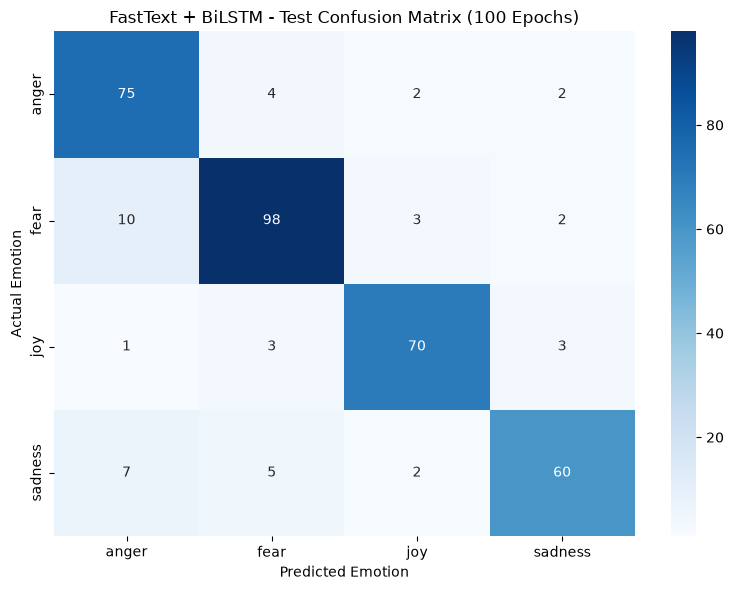

In [134]:

# ============================================================
# FASTTEXT + BILSTM - TEST SET EVALUATION (100 EPOCHS)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Generate test predictions
y_test_prob_fasttext_bilstm_100 = (
    fasttext_bilstm_model.predict(
        X_test_padded,
        verbose=1
    )
)

y_test_pred_fasttext_bilstm_100 = np.argmax(
    y_test_prob_fasttext_bilstm_100,
    axis=1
)

y_test_actual = y_test_encoded

# Calculate evaluation metrics
accuracy_100 = accuracy_score(
    y_test_actual,
    y_test_pred_fasttext_bilstm_100
)

precision_100 = precision_score(
    y_test_actual,
    y_test_pred_fasttext_bilstm_100,
    average="macro",
    zero_division=0
)

recall_100 = recall_score(
    y_test_actual,
    y_test_pred_fasttext_bilstm_100,
    average="macro",
    zero_division=0
)

f1_100 = f1_score(
    y_test_actual,
    y_test_pred_fasttext_bilstm_100,
    average="macro",
    zero_division=0
)

print("=" * 60)
print("FASTTEXT + BILSTM - TEST EVALUATION (100 EPOCHS)")
print("=" * 60)

print(f"Accuracy  : {accuracy_100:.4f}")
print(f"Precision : {precision_100:.4f}")
print(f"Recall    : {recall_100:.4f}")
print(f"F1-Score  : {f1_100:.4f}")

# Classification report
print("\nClassification Report:\n")

print(
    classification_report(
        y_test_actual,
        y_test_pred_fasttext_bilstm_100,
        labels=np.arange(num_classes),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# Confusion matrix
cm_100 = confusion_matrix(
    y_test_actual,
    y_test_pred_fasttext_bilstm_100,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_100,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("FastText + BiLSTM - Test Confusion Matrix (100 Epochs)")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.show()


In [135]:

# ============================================================
# FURTHER HYPERPARAMETER TUNING - FASTTEXT + BILSTM
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    SpatialDropout1D,
    Bidirectional,
    LSTM,
    Dense,
    Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

from sklearn.metrics import f1_score

# ------------------------------------------------------------
# DEFINE HYPERPARAMETER CONFIGURATIONS
# ------------------------------------------------------------

configs_bilstm = [
    {
        "name": "Baseline",
        "units": 128,
        "spatial_dropout": 0.25,
        "lstm_dropout": 0.25,
        "dense_dropout": 0.40,
        "learning_rate": 0.001,
        "batch_size": 32
    },
    {
        "name": "Higher Regularization",
        "units": 128,
        "spatial_dropout": 0.35,
        "lstm_dropout": 0.35,
        "dense_dropout": 0.50,
        "learning_rate": 0.0005,
        "batch_size": 32
    },
    {
        "name": "Smaller BiLSTM",
        "units": 64,
        "spatial_dropout": 0.30,
        "lstm_dropout": 0.30,
        "dense_dropout": 0.40,
        "learning_rate": 0.0005,
        "batch_size": 32
    }
]

EPOCHS = 50

tuning_results_bilstm = []
tuning_models_bilstm = []
tuning_histories_bilstm = []

# Actual validation labels
y_val_actual = np.argmax(y_val_cat, axis=1)

# ------------------------------------------------------------
# RUN EXPERIMENTS
# ------------------------------------------------------------

for i, config in enumerate(configs_bilstm, start=1):

    print("\n" + "=" * 65)
    print(f"FASTTEXT + BILSTM - EXPERIMENT {i}/3")
    print("Configuration:", config["name"])
    print("=" * 65)

    tf.keras.utils.set_random_seed(42)

    # Build model
    tuned_model = Sequential([
        Input(
            shape=(X_train_padded.shape[1],),
            dtype="int32"
        ),

        Embedding(
            input_dim=embedding_matrix_fasttext.shape[0],
            output_dim=embedding_matrix_fasttext.shape[1],
            weights=[embedding_matrix_fasttext],
            trainable=True,
            mask_zero=True
        ),

        SpatialDropout1D(
            config["spatial_dropout"]
        ),

        Bidirectional(
            LSTM(
                config["units"],
                dropout=config["lstm_dropout"]
            )
        ),

        Dense(
            32,
            activation="relu",
            kernel_regularizer=l2(0.001)
        ),

        Dropout(config["dense_dropout"]),

        Dense(num_classes, activation="softmax")
    ])

    # Compile model
    tuned_model.compile(
        optimizer=Adam(
            learning_rate=config["learning_rate"]
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Train for 50 complete epochs
    tuned_history = tuned_model.fit(
        X_train_padded,
        y_train_cat,
        validation_data=(X_val_padded, y_val_cat),
        epochs=EPOCHS,
        batch_size=config["batch_size"],
        verbose=1,
        shuffle=True
    )

    # Validation predictions
    val_prob = tuned_model.predict(
        X_val_padded,
        verbose=0
    )

    val_pred = np.argmax(val_prob, axis=1)

    # Select configuration using validation Macro F1
    val_f1 = f1_score(
        y_val_actual,
        val_pred,
        average="macro",
        zero_division=0
    )

    tuning_results_bilstm.append({
        "Configuration": config["name"],
        "Units": config["units"],
        "Spatial Dropout": config["spatial_dropout"],
        "LSTM Dropout": config["lstm_dropout"],
        "Dense Dropout": config["dense_dropout"],
        "Learning Rate": config["learning_rate"],
        "Batch Size": config["batch_size"],
        "Train Accuracy": tuned_history.history["accuracy"][-1],
        "Validation Accuracy": tuned_history.history["val_accuracy"][-1],
        "Validation Loss": tuned_history.history["val_loss"][-1],
        "Validation Macro F1": val_f1
    })

    tuning_models_bilstm.append(tuned_model)
    tuning_histories_bilstm.append(tuned_history)

    print(f"Validation Macro F1: {val_f1:.4f}")


# ------------------------------------------------------------
# COMPARE CONFIGURATIONS
# ------------------------------------------------------------

tuning_df_bilstm = pd.DataFrame(tuning_results_bilstm)

print("\n" + "=" * 75)
print("FASTTEXT + BILSTM - FURTHER TUNING RESULTS")
print("=" * 75)

display(
    tuning_df_bilstm.sort_values(
        by="Validation Macro F1",
        ascending=False
    ).round(4).reset_index(drop=True)
)

# ------------------------------------------------------------
# SELECT BEST CONFIGURATION
# ------------------------------------------------------------

best_idx_bilstm = int(
    np.argmax(
        tuning_df_bilstm["Validation Macro F1"].values
    )
)

best_tuned_fasttext_bilstm = tuning_models_bilstm[best_idx_bilstm]
best_tuned_history_bilstm = tuning_histories_bilstm[best_idx_bilstm]
best_tuned_config_bilstm = configs_bilstm[best_idx_bilstm]

print("\nBest Configuration:", best_tuned_config_bilstm)
print(
    "Best Validation Macro F1:",
    round(
        tuning_df_bilstm.loc[
            best_idx_bilstm, "Validation Macro F1"
        ],
        4
    )
)

print("\nFurther Hyperparameter Tuning Completed!")



FASTTEXT + BILSTM - EXPERIMENT 1/3
Configuration: Baseline
Epoch 1/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 11s 43ms/step - accuracy: 0.3034 - loss: 1.4411 - val_accuracy: 0.3228 - val_loss: 1.4177
Epoch 2/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.3175 - loss: 1.4153 - val_accuracy: 0.3228 - val_loss: 1.4013
Epoch 3/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.3236 - loss: 1.3979 - val_accuracy: 0.3256 - val_loss: 1.3847
Epoch 4/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.3553 - loss: 1.3555 - val_accuracy: 0.4265 - val_loss: 1.2752
Epoch 5/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.4649 - loss: 1.1630 - val_accuracy: 0.5331 - val_loss: 1.0666
Epoch 6/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.5596 - loss: 0.9264 - val_accuracy: 0.5677 - val_loss: 0.9547
Epoch 7/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.6919 - loss: 0.7180 - val_accuracy: 0.6369 - val_loss: 0.9327
Epoch 8/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step

,Configuration,Units,Spatial Dropout,LSTM Dropout,Dense Dropout,Learning Rate,Batch Size,Train Accuracy,Validation Accuracy,Validation Loss,Validation Macro F1
0,Baseline,128,0.25,0.25,0.4,0.0010,32,0.9986,0.8905,0.6414,0.8859
1,Smaller BiLSTM,64,0.30,0.30,0.4,0.0005,32,0.9935,0.8761,0.6918,0.8743
2,Higher Regularization,128,0.35,0.35,0.5,0.0005,32,0.9881,0.8040,0.9825,0.8016



Best Configuration: {'name': 'Baseline', 'units': 128, 'spatial_dropout': 0.25, 'lstm_dropout': 0.25, 'dense_dropout': 0.4, 'learning_rate': 0.001, 'batch_size': 32}
Best Validation Macro F1: 0.8859

Further Hyperparameter Tuning Completed!


In [136]:

# ============================================================
# BEST TUNED FASTTEXT + BILSTM - CONTINUE UP TO 100 EPOCHS
# ============================================================

EPOCHS = 100
BATCH_SIZE = 32

history_best_bilstm_100 = best_tuned_fasttext_bilstm.fit(
    X_train_padded,
    y_train_cat,
    validation_data=(X_val_padded, y_val_cat),
    initial_epoch=50,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
    shuffle=True
)

print("Best Tuned FastText + BiLSTM Training Completed!")
print("Total Epochs: 100")


Epoch 51/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.9921 - loss: 0.0346 - val_accuracy: 0.8617 - val_loss: 0.6028
Epoch 52/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.9968 - loss: 0.0194 - val_accuracy: 0.8790 - val_loss: 0.5743
Epoch 53/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.9975 - loss: 0.0173 - val_accuracy: 0.8876 - val_loss: 0.5980
Epoch 54/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.9968 - loss: 0.0197 - val_accuracy: 0.8847 - val_loss: 0.6489
Epoch 55/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.9986 - loss: 0.0159 - val_accuracy: 0.8876 - val_loss: 0.6432
Epoch 56/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.9950 - loss: 0.0215 - val_accuracy: 0.8934 - val_loss: 0.6077
Epoch 57/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.9971 - loss: 0.0149 - val_accuracy: 0.8876 - val_loss: 0.6465
Epoch 58/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.9946 - loss: 0.0249 - val_accu

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step
TUNED FASTTEXT + BILSTM - TEST EVALUATION (100 EPOCHS)
Accuracy  : 0.8501
Precision : 0.8463
Recall    : 0.8439
F1-Score  : 0.8447

Classification Report:

              precision    recall  f1-score   support

       anger       0.82      0.87      0.84        83
        fear       0.89      0.89      0.89       113
         joy       0.87      0.84      0.86        77
     sadness       0.81      0.77      0.79        74

    accuracy                           0.85       347
   macro avg       0.85      0.84      0.84       347
weighted avg       0.85      0.85      0.85       347



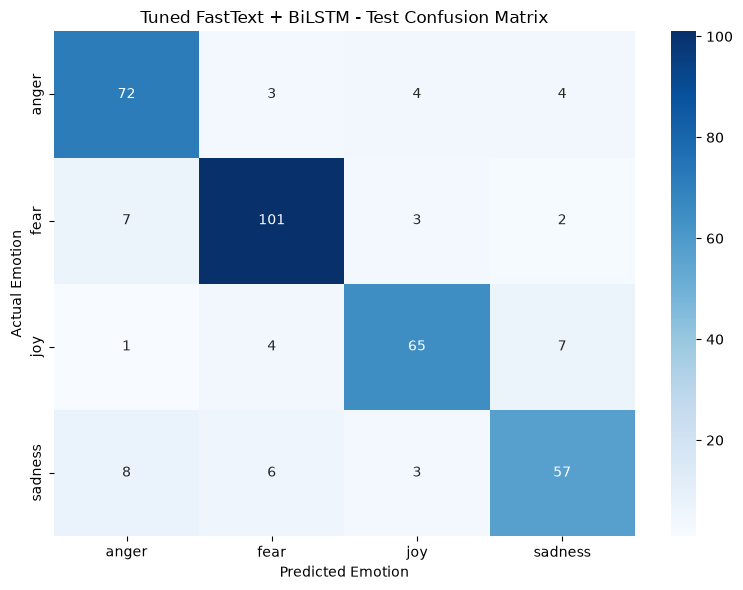

In [137]:

# ============================================================
# BEST TUNED FASTTEXT + BILSTM - TEST SET EVALUATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Generate test predictions
y_test_prob_tuned_bilstm_100 = (
    best_tuned_fasttext_bilstm.predict(
        X_test_padded,
        verbose=1
    )
)

y_test_pred_tuned_bilstm_100 = np.argmax(
    y_test_prob_tuned_bilstm_100,
    axis=1
)

y_test_actual = y_test_encoded

# Calculate evaluation metrics
accuracy_tuned_100 = accuracy_score(
    y_test_actual,
    y_test_pred_tuned_bilstm_100
)

precision_tuned_100 = precision_score(
    y_test_actual,
    y_test_pred_tuned_bilstm_100,
    average="macro",
    zero_division=0
)

recall_tuned_100 = recall_score(
    y_test_actual,
    y_test_pred_tuned_bilstm_100,
    average="macro",
    zero_division=0
)

f1_tuned_100 = f1_score(
    y_test_actual,
    y_test_pred_tuned_bilstm_100,
    average="macro",
    zero_division=0
)

print("=" * 60)
print("TUNED FASTTEXT + BILSTM - TEST EVALUATION (100 EPOCHS)")
print("=" * 60)

print(f"Accuracy  : {accuracy_tuned_100:.4f}")
print(f"Precision : {precision_tuned_100:.4f}")
print(f"Recall    : {recall_tuned_100:.4f}")
print(f"F1-Score  : {f1_tuned_100:.4f}")

# Classification Report
print("\nClassification Report:\n")

print(
    classification_report(
        y_test_actual,
        y_test_pred_tuned_bilstm_100,
        labels=np.arange(num_classes),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# Confusion Matrix
cm_tuned_bilstm_100 = confusion_matrix(
    y_test_actual,
    y_test_pred_tuned_bilstm_100,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_tuned_bilstm_100,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Tuned FastText + BiLSTM - Test Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.show()


In [138]:

# ============================================================
# FASTTEXT + BILSTM - 100 EPOCHS WITH BEST MACRO F1 CHECKPOINT
# ============================================================

import numpy as np
import tensorflow as tf

from sklearn.metrics import f1_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    SpatialDropout1D,
    Bidirectional,
    LSTM,
    Dense,
    Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

# ------------------------------------------------------------
# CALLBACK: SAVE BEST VALIDATION MACRO F1 WEIGHTS
# ------------------------------------------------------------

class BestMacroF1Checkpoint(tf.keras.callbacks.Callback):

    def __init__(self, X_val, y_val, filepath):
        super().__init__()

        self.X_val = X_val
        self.y_val = np.argmax(y_val, axis=1)
        self.filepath = filepath

        self.best_f1 = -1.0
        self.best_epoch = 0
        self.f1_scores = []

    def on_epoch_end(self, epoch, logs=None):

        val_prob = self.model.predict(
            self.X_val,
            verbose=0
        )

        val_pred = np.argmax(val_prob, axis=1)

        val_macro_f1 = f1_score(
            self.y_val,
            val_pred,
            average="macro",
            zero_division=0
        )

        self.f1_scores.append(val_macro_f1)

        if val_macro_f1 > self.best_f1:
            self.best_f1 = val_macro_f1
            self.best_epoch = epoch + 1

            self.model.save_weights(self.filepath)

            print(
                f"\nBest checkpoint saved: "
                f"Epoch {self.best_epoch}, "
                f"Validation Macro F1 = {self.best_f1:.4f}"
            )


# ------------------------------------------------------------
# BUILD FRESH FASTTEXT + BILSTM MODEL
# ------------------------------------------------------------

tf.keras.utils.set_random_seed(42)

final_fasttext_bilstm_model = Sequential([
    Input(
        shape=(X_train_padded.shape[1],),
        dtype="int32"
    ),

    Embedding(
        input_dim=embedding_matrix_fasttext.shape[0],
        output_dim=embedding_matrix_fasttext.shape[1],
        weights=[embedding_matrix_fasttext],
        trainable=True,
        mask_zero=True
    ),

    SpatialDropout1D(0.25),

    Bidirectional(
        LSTM(128, dropout=0.25)
    ),

    Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dropout(0.4),

    Dense(num_classes, activation="softmax")
])

final_fasttext_bilstm_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# ------------------------------------------------------------
# TRAIN FOR EXACTLY 100 EPOCHS
# ------------------------------------------------------------

checkpoint_path = "best_fasttext_bilstm.weights.h5"

macro_f1_checkpoint = BestMacroF1Checkpoint(
    X_val=X_val_padded,
    y_val=y_val_cat,
    filepath=checkpoint_path
)

history_final_bilstm = final_fasttext_bilstm_model.fit(
    X_train_padded,
    y_train_cat,
    validation_data=(X_val_padded, y_val_cat),
    epochs=100,
    batch_size=32,
    verbose=1,
    shuffle=True,
    callbacks=[macro_f1_checkpoint]
)

# ------------------------------------------------------------
# LOAD BEST VALIDATION MACRO F1 WEIGHTS
# ------------------------------------------------------------

final_fasttext_bilstm_model.load_weights(checkpoint_path)

print("\n" + "=" * 60)
print("BEST FASTTEXT + BILSTM CHECKPOINT")
print("=" * 60)

print("Total Epochs Trained: 100")
print("Best Epoch:", macro_f1_checkpoint.best_epoch)
print(
    "Best Validation Macro F1:",
    round(macro_f1_checkpoint.best_f1, 4)
)

print("Best weights file:", checkpoint_path)
print("Best checkpoint loaded successfully!")


Epoch 1/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.3034 - loss: 1.4411
Best checkpoint saved: Epoch 1, Validation Macro F1 = 0.1220
87/87 ━━━━━━━━━━━━━━━━━━━━ 13s 61ms/step - accuracy: 0.3034 - loss: 1.4411 - val_accuracy: 0.3228 - val_loss: 1.4177
Epoch 2/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.3171 - loss: 1.4132 - val_accuracy: 0.3228 - val_loss: 1.4010
Epoch 3/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.3229 - loss: 1.3982 - val_accuracy: 0.3228 - val_loss: 1.3858
Epoch 4/100
86/87 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.3456 - loss: 1.3542
Best checkpoint saved: Epoch 4, Validation Macro F1 = 0.2369
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.3470 - loss: 1.3534 - val_accuracy: 0.3660 - val_loss: 1.3335
Epoch 5/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.4627 - loss: 1.1609
Best checkpoint saved: Epoch 5, Validation Macro F1 = 0.3726
87/87 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.4627 - loss: 1.1

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
BEST FASTTEXT + BILSTM CHECKPOINT - TEST EVALUATION
Best Epoch: 85
Accuracy  : 0.8444
Precision : 0.8386
Recall    : 0.8348
Macro F1  : 0.8362

Classification Report:

              precision    recall  f1-score   support

       anger       0.84      0.83      0.84        83
        fear       0.88      0.92      0.90       113
         joy       0.82      0.84      0.83        77
     sadness       0.81      0.74      0.77        74

    accuracy                           0.84       347
   macro avg       0.84      0.83      0.84       347
weighted avg       0.84      0.84      0.84       347



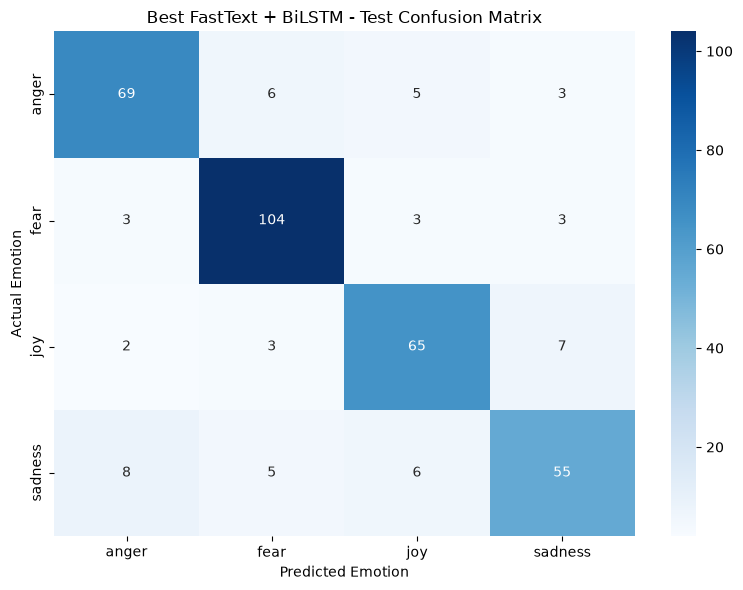

In [139]:

# ============================================================
# BEST FASTTEXT + BILSTM CHECKPOINT - TEST EVALUATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# GENERATE TEST PREDICTIONS
# ------------------------------------------------------------

y_test_prob_best = final_fasttext_bilstm_model.predict(
    X_test_padded,
    verbose=1
)

y_test_pred_best = np.argmax(
    y_test_prob_best,
    axis=1
)

y_test_actual = y_test_encoded

# ------------------------------------------------------------
# CALCULATE METRICS
# ------------------------------------------------------------

accuracy_best = accuracy_score(
    y_test_actual, y_test_pred_best
)

precision_best = precision_score(
    y_test_actual,
    y_test_pred_best,
    average="macro",
    zero_division=0
)

recall_best = recall_score(
    y_test_actual,
    y_test_pred_best,
    average="macro",
    zero_division=0
)

f1_best = f1_score(
    y_test_actual,
    y_test_pred_best,
    average="macro",
    zero_division=0
)

print("=" * 60)
print("BEST FASTTEXT + BILSTM CHECKPOINT - TEST EVALUATION")
print("=" * 60)

print(f"Best Epoch: {macro_f1_checkpoint.best_epoch}")
print(f"Accuracy  : {accuracy_best:.4f}")
print(f"Precision : {precision_best:.4f}")
print(f"Recall    : {recall_best:.4f}")
print(f"Macro F1  : {f1_best:.4f}")

# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\nClassification Report:\n")

print(
    classification_report(
        y_test_actual,
        y_test_pred_best,
        labels=np.arange(num_classes),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

cm_best = confusion_matrix(
    y_test_actual,
    y_test_pred_best,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_best,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Best FastText + BiLSTM - Test Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.show()


In [140]:

# ============================================================
# SAVE BEST VALIDATION CHECKPOINT - FASTTEXT + BILSTM
# ============================================================

import pickle
import json

# Save complete model with Epoch 85 weights
final_fasttext_bilstm_model.save(
    "best_fasttext_bilstm.keras"
)

# Save tokenizer
with open("tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

# Save label encoder
with open("label_encoder.pkl", "wb") as file:
    pickle.dump(label_encoder, file)

# Save configuration
config = {
    "max_len": int(X_train_padded.shape[1]),
    "num_classes": int(num_classes),
    "embedding_dim": int(embedding_matrix_fasttext.shape[1]),
    "emotion_classes": label_encoder.classes_.tolist(),
    "best_epoch": int(macro_f1_checkpoint.best_epoch),
    "validation_macro_f1": float(macro_f1_checkpoint.best_f1)
}

with open("model_config.json", "w") as file:
    json.dump(config, file, indent=4)

print("Best validation checkpoint saved successfully!")
print("1. best_fasttext_bilstm.keras")
print("2. tokenizer.pkl")
print("3. label_encoder.pkl")
print("4. model_config.json")


Best validation checkpoint saved successfully!
1. best_fasttext_bilstm.keras
2. tokenizer.pkl
3. label_encoder.pkl
4. model_config.json


In [141]:
# ============================================================
# LOAD SAVED MODEL AND PREDICT EMOTIONS
# ============================================================

import numpy as np
import pickle
import json

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Load saved model
model = load_model("best_fasttext_bilstm.keras", compile=False)

# Load tokenizer
with open("tokenizer.pkl", "rb") as file:
    tokenizer = pickle.load(file)

# Load label encoder
with open("label_encoder.pkl", "rb") as file:
    label_encoder = pickle.load(file)

# Load model configuration
with open("model_config.json", "r") as file:
    config = json.load(file)

max_len = config["max_len"]

print("Saved model and required files loaded successfully!")


# ============================================================
# PREDICT EMOTION FOR A NEW SENTENCE
# ============================================================

def predict_emotion(sentence):

    # Use the same text cleaning function used during training
    cleaned_sentence = clean_text(sentence)

    # Convert text into sequences
    sequence = tokenizer.texts_to_sequences([cleaned_sentence])

    # Pad sequence to the training length
    padded_sequence = pad_sequences(
        sequence,
        maxlen=max_len,
        padding="post",
        truncating="post"
    )

    # Predict emotion probabilities
    probabilities = model.predict(padded_sequence, verbose=0)[0]

    # Get the predicted class
    predicted_index = int(np.argmax(probabilities))
    predicted_emotion = label_encoder.inverse_transform(
        [predicted_index]
    )[0]

    model_score = float(probabilities[predicted_index]) * 100

    print("Input Sentence :", sentence)
    print("Predicted Emotion:", predicted_emotion)
    print("Model Score      :", f"{model_score:.2f}%")

    return predicted_emotion


# ============================================================
# TEST WITH NEW SENTENCES
# ============================================================

predict_emotion("I am very happy today.")

print()

predict_emotion("I am scared about my exam.")

print()

predict_emotion("I feel angry about what happened.")

print()

predict_emotion("I miss my family and feel sad.")

Saved model and required files loaded successfully!
Input Sentence : I am very happy today.
Predicted Emotion: joy
Model Score      : 100.00%

Input Sentence : I am scared about my exam.
Predicted Emotion: fear
Model Score      : 100.00%

Input Sentence : I feel angry about what happened.
Predicted Emotion: anger
Model Score      : 100.00%

Input Sentence : I miss my family and feel sad.
Predicted Emotion: sadness
Model Score      : 99.98%


'sadness'